# Analyse de la Base de Données Installations des Produits CNI

## I. Exploration et Nettoyage des données :

## 1. Compréhension des données

### 1.1 Importation des librairies

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.feature_selection import mutual_info_classif, mutual_info_regression
from scipy.stats import chi2_contingency
import plotly.express as px
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score,
                             classification_report, confusion_matrix,
                             mean_squared_error, mean_absolute_error, r2_score)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor

import warnings
warnings.filterwarnings("ignore")

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

# Style général
sns.set_theme(style="whitegrid")

plt.rcParams.update({
    "figure.figsize": (9, 5),
    "figure.dpi": 120,
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 12,
    "axes.grid": True,
    "grid.alpha": 0.3,
})
sns.set_palette(["#6d6fd630"])

### 1.2 Chargement des données

In [3]:
df = pd.read_csv("base_de_donnees_installations_produits_CNI.csv", delimiter=";", encoding="cp1252")

### 1.3 Aperçu du dataset

* Premières observations :

In [4]:
df.head()

,Nom_produit,version_produit,date_installation,Gouvernorat,Id_Client,Type_client,Systeme_exploitation_poste,installation_reussie,nombre_essais_installation,client_a_reclame,nombre_reclamations_client,client_satisfait,Remarques,Technicien_ID,Duree_installation_minutes,Debit_reseau_Mbps,Taille_site_postes,Mode_installation,Tentative_installation_weekend,Version_precedente
0,INSAF,1.1,2019-02-24,Gafsa,CIN10000,Ministère,Windows 2012 Server,non,5,oui,2,non,problème réseau,TECH_038,139,"4,43",15,Technicien_sur_site,oui,1.0
1,INSAF,2.1,2021-02-13,Tunis,CIN10001,Ministère,Windows 2012 Server,non,5,oui,4,non,version incompatible,TECH_045,163,"35,34",21,Technicien_sur_site,oui,1.1
2,INSAF,3.0,2018-06-27,Kébili,CIN10002,Ministère,Win11,non,3,oui,2,non,Problème adressage ip,TECH_035,55,"97,37",17,Télémaintenance,oui,2.0
3,INSAF,3.0,2021-03-31,Ben Arous,CIN10003,EPA,Windows 2008 Server,oui,3,oui,0,non,erreur configuration poste,TECH_007,112,"29,24",9,Télémaintenance,oui,1.1
4,INSAF,2.2,2019-12-02,Sidi Bouzid,CIN10004,EPA,Windows 2012 Server,non,5,oui,5,non,erreur configuration poste,TECH_011,143,"39,19",7,Technicien_sur_site,non,0.9


* Forme du dataframe :

In [5]:
df.shape

(15272, 20)

On a 8200 lignes et 20 colonnes

* Types des données :

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15272 entries, 0 to 15271
Data columns (total 20 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Nom_produit                     15272 non-null  str    
 1   version_produit                 15272 non-null  float64
 2   date_installation               15272 non-null  str    
 3   Gouvernorat                     15272 non-null  str    
 4   Id_Client                       15097 non-null  str    
 5   Type_client                     15272 non-null  str    
 6   Systeme_exploitation_poste      15272 non-null  str    
 7   installation_reussie            15175 non-null  str    
 8   nombre_essais_installation      15272 non-null  int64  
 9   client_a_reclame                15272 non-null  str    
 10  nombre_reclamations_client      15272 non-null  int64  
 11  client_satisfait                15272 non-null  str    
 12  Remarques                       8236 non-nu

Dans la table on a 4 variables de type entier(`int64`), une variable de type réel(`float64`) et 15 variables de type chaine de caractères(`object`)
On constate que :
- `date_installation` est de type `object` et on doit la changer en type `date_time`
- `Debit_reseau_Mbps` est de type `object` et on doit la changer en type `float64`
- `version_produit` est de type `float64`et on doit la changer en type `object`
- on doit encoder les variables `installation_reussie`, `client_a_reclame`, `client_satisfait` et `Tentative_installation_weekend` et `Mode_installation` (oui : 1 et non : 0)

* Duplication :

In [7]:
df.duplicated().sum()

np.int64(118)

Dans le csv il y a 118 lignes dupliquées

## 2. Nettoyage initial des données
Objectif : corriger les problèmes évidents avant l’analyse exploratoire.

    - on doit changer la colonne `date_installation` en type Date 
    - changer le `Debit_reseau_Mbps` en reel du type `float64`

### 2.1 Correction des types de données

In [8]:
df['date_installation'] = pd.to_datetime(df['date_installation'], errors='coerce')

In [9]:
df['Debit_reseau_Mbps'] = df['Debit_reseau_Mbps'].str.replace(",", ".").astype(float)

In [10]:
df['Version_precedente'] = df['Version_precedente'].str.replace('aucune','0')
df['Version_precedente'].value_counts()

Version_precedente
1.0    2578
0.9    2576
0      2568
1.1    2533
2.0    2523
1.2    2494
Name: count, dtype: int64

In [11]:
df['version_produit'] = df['version_produit'].astype(object)

In [12]:
# Pour vérifier les types de données après les conversions 
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15272 entries, 0 to 15271
Data columns (total 20 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   Nom_produit                     15272 non-null  str           
 1   version_produit                 15272 non-null  object        
 2   date_installation               15272 non-null  datetime64[us]
 3   Gouvernorat                     15272 non-null  str           
 4   Id_Client                       15097 non-null  str           
 5   Type_client                     15272 non-null  str           
 6   Systeme_exploitation_poste      15272 non-null  str           
 7   installation_reussie            15175 non-null  str           
 8   nombre_essais_installation      15272 non-null  int64         
 9   client_a_reclame                15272 non-null  str           
 10  nombre_reclamations_client      15272 non-null  int64         
 11  client_satisf

### 2.2 Suppression des doublons

In [13]:
df.drop_duplicates(inplace=True)

## 3. Analyse exploratoire des données (EDA)

### Analyse descriptive:
    Objectif : L’analyse descriptive a pour objectif d’expliquer ce qui s’est passé dans le passé. Elle se concentre sur l’analyse des données historiques afin d’identifier des tendances, des patterns et d’obtenir des résumés pertinents. Elle repose sur les statistiques descriptives, qui consistent à résumer et organiser les données pour décrire leurs principales caractéristiques. Cela inclut les mesures de tendance centrale (moyenne, médiane, mode), les mesures de dispersion (étendue, variance, écart-type) ainsi que les visualisations (histogrammes, diagrammes en barres, boîtes à moustaches). L’analyse descriptive permet ainsi de mieux comprendre la structure et l’aspect général des données.

### 3.1 Détection des valeurs manquantes

In [14]:
df.isna().sum()

Nom_produit                          0
version_produit                      0
date_installation                    0
Gouvernorat                          0
Id_Client                          174
Type_client                          0
Systeme_exploitation_poste           0
installation_reussie                97
nombre_essais_installation           0
client_a_reclame                     0
nombre_reclamations_client           0
client_satisfait                     0
Remarques                         6976
Technicien_ID                        0
Duree_installation_minutes           0
Debit_reseau_Mbps                    0
Taille_site_postes                   0
Mode_installation                    0
Tentative_installation_weekend       0
Version_precedente                   0
dtype: int64

Il y a troix variables qui ont des valeurs manquantes : `Id_Client`, `installation_reussie` et `Remarques`.

### 3.2 Détection des données inconsistante :

In [15]:
df['Systeme_exploitation_poste'].value_counts()

Systeme_exploitation_poste
Win10                  2342
Win11                  2309
Windows server 2022    1957
Windows server 2019    1939
Windows server 2016    1930
Win8                   1113
Windows 2012 Server    1104
Win7                   1103
Windows 2008 Server    1090
WindowsXP               101
win10                    60
Unknown                  56
Win 10                   50
Name: count, dtype: int64

- on constate qu'il existe un incoherence des donnes dans la colonne `Systeme_exploitation_poste` pour les valeurs `win10` et `Win 10` et `Win10`

- Il existe des postes avec des system d'exploitation  `Unknown`, et on doit faire une analyse

### 3.3 Detection des valeurs inhabituelles :

nombre_reclamations_client
 0     6772
 3     1695
 1     1693
 2     1663
 4     1663
 6      741
 5      731
 25     103
-2       93
Name: count, dtype: int64


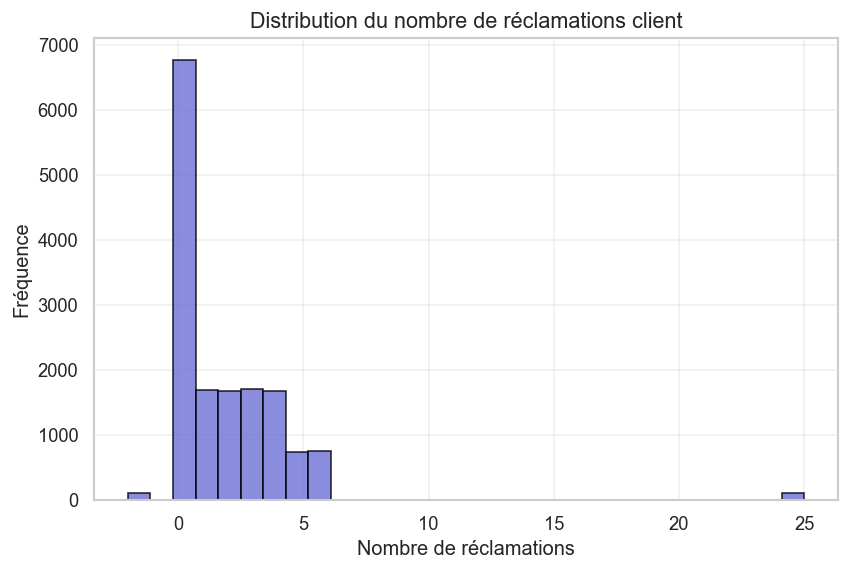

In [16]:
print(df['nombre_reclamations_client'].value_counts())
plt.figure(figsize=(8,5))
plt.hist(df['nombre_reclamations_client'], bins=30, alpha=0.8, edgecolor="black")
plt.title("Distribution du nombre de réclamations client")
plt.xlabel("Nombre de réclamations")
plt.ylabel("Fréquence")
plt.show()

Dans la colonne `nombre_reclamations_client`, des valeurs abherente ont été détectées, notamment  `-2` et `25` 
- la valeur `-2` est incohérente , car le nombre de reclamations ne peut pas etre negatif.
- la valeur  `25` semble anormalement élevée par rapport au reste des valeurs.

Version_precedente
1.0    2557
0.9    2553
0      2535
1.1    2518
2.0    2514
1.2    2477
Name: count, dtype: int64


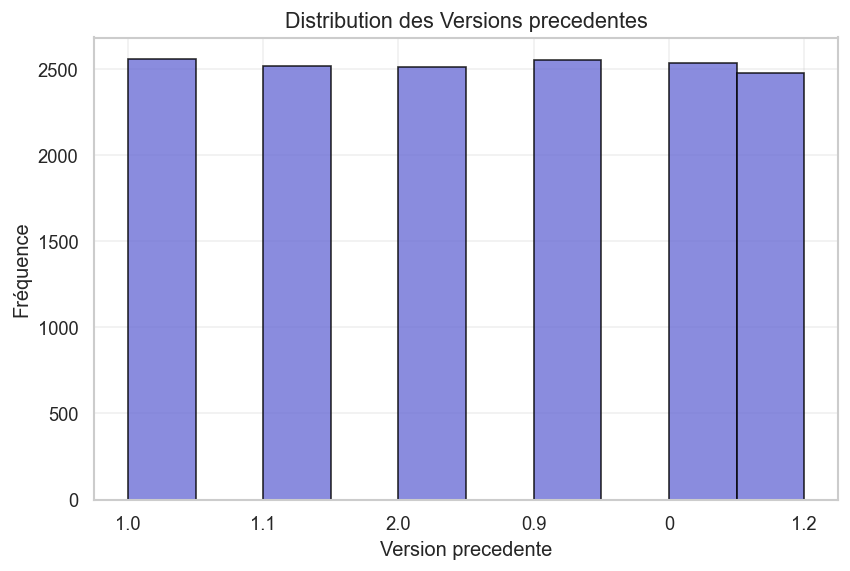

In [17]:
print(df['Version_precedente'].value_counts())
plt.figure(figsize=(8,5))
plt.hist(df['Version_precedente'],alpha=0.8, edgecolor="black")
plt.title("Distribution des Versions precedentes")
plt.xlabel("Version precedente")
plt.ylabel("Fréquence")
plt.show()

On a 1311 clients qui n'ont pas de version précedente on va alors transformer aucune en 0

date_installation
2019    2036
2023    1967
2021    1962
2020    1951
2022    1949
2018    1920
2024    1858
2025    1511
Name: count, dtype: int64


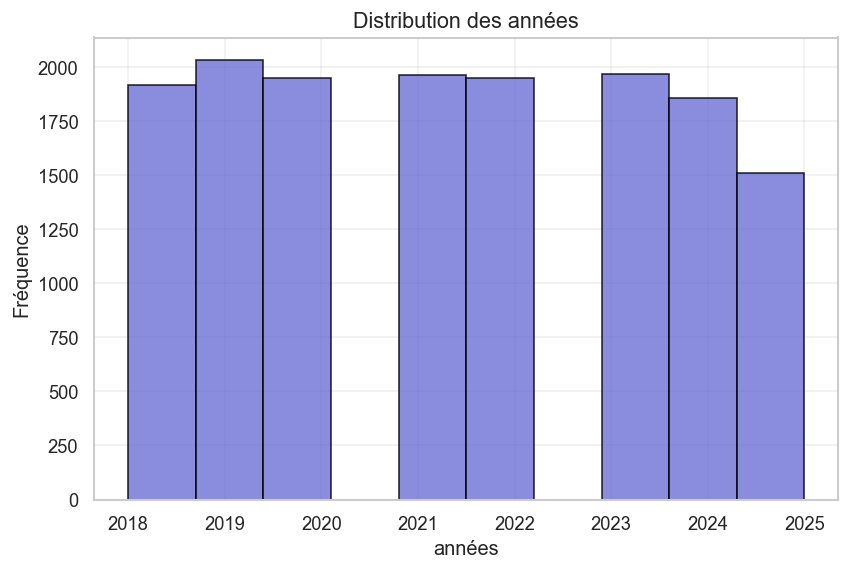

In [18]:
years = df['date_installation'].dt.year
print(years.value_counts())
plt.figure(figsize=(8,5))
plt.hist(years,alpha=0.8, edgecolor="black")
plt.title("Distribution des années")
plt.xlabel("années")
plt.ylabel("Fréquence")
plt.show()

Remplacer les valeurs `aucune` dans la variable `Version_precedente`

### 3.4 Analyse statistique des variables qualitatives

In [19]:
df.describe()

,date_installation,nombre_essais_installation,nombre_reclamations_client,Duree_installation_minutes,Debit_reseau_Mbps,Taille_site_postes
count,15154,15154.000000,15154.000000,15154.000000,15154.000000,15154.000000
mean,2021-11-14 14:19:01.243236,3.551538,1.797941,95.092715,47.301893,13.102613
min,2018-01-01 00:00:00,1.000000,-2.000000,30.000000,0.010000,1.000000
25%,2019-11-30 00:00:00,2.000000,0.000000,57.000000,19.225000,6.000000
50%,2021-11-09 00:00:00,4.000000,1.000000,96.000000,47.160000,11.000000
75%,2023-10-16 00:00:00,5.000000,3.000000,130.000000,73.660000,20.000000
max,2025-12-31 00:00:00,5.000000,25.000000,202.000000,100.000000,30.000000
std,NaN,1.651883,2.705542,43.276784,30.143951,8.309175


d'après le tableau ci dessus on a les statistique suivantes:
- l'existence d'une date future dans la colonne `date_installation` ce qui est absurde 
- moyenne du `nombre_essais_installation` est de 2.98, qui est moyen par rapport au nombre d'essais qui varie entre 1 et 5
- moyenne du `nombre_reclamations_client` est de 2.83, le moyenne est proche de la mediane ce qui indique une ue distribution symetrique  on constate que `le coefficient de variation` est egale a 0.865 ce qui insique une dispersion forte des données donc possibilité d'avoir des valeurs aberrantes
- `Duree_installation_minutes` et `Debit_reseau_Mbps` il ya une possibilitées d'avoir des valeurs aberrantes dans ces deux variables du l'ecart important entre l'ecart-type et la distribution des données entre les quartiles.
- l’écart type (46.1)  de la variables `Duree_installation_minutes` indique que certaines installations sont beaucoup plus rapides ou lentes que la moyenne.

### 3.5 Analyse statistique des variables quantitatives

In [20]:
df.describe(include='object')

,Nom_produit,version_produit,Gouvernorat,Id_Client,Type_client,Systeme_exploitation_poste,installation_reussie,client_a_reclame,client_satisfait,Remarques,Technicien_ID,Mode_installation,Tentative_installation_weekend,Version_precedente
count,15154,15154.0,15154,14980,15154,15154,15057,15154,15154,8178,15154,15154,15154,15154
unique,4,7.0,24,12715,4,13,2,2,2,7,50,2,2,6
top,MAKATIB,1.0,Ariana,CMA10328,EPNA,Win10,non,oui,non,version incompatible,TECH_045,Technicien_sur_site,non,1.0
freq,3830,2299.0,691,4,3864,2342,7801,8972,8632,2891,337,7590,7715,2557


### 3.6 Covariance

In [21]:
df_num = df.select_dtypes(include=[np.number])
cov = df_num.cov()
cov

,nombre_essais_installation,nombre_reclamations_client,Duree_installation_minutes,Debit_reseau_Mbps,Taille_site_postes
nombre_essais_installation,2.728717,2.342428,51.933154,-17.834336,-3.130050
nombre_reclamations_client,2.342428,7.319956,49.032858,-17.294219,-2.829789
Duree_installation_minutes,51.933154,49.032858,1872.880006,-813.984373,2.293594
Debit_reseau_Mbps,-17.834336,-17.294219,-813.984373,908.657790,17.860486
Taille_site_postes,-3.130050,-2.829789,2.293594,17.860486,69.042397


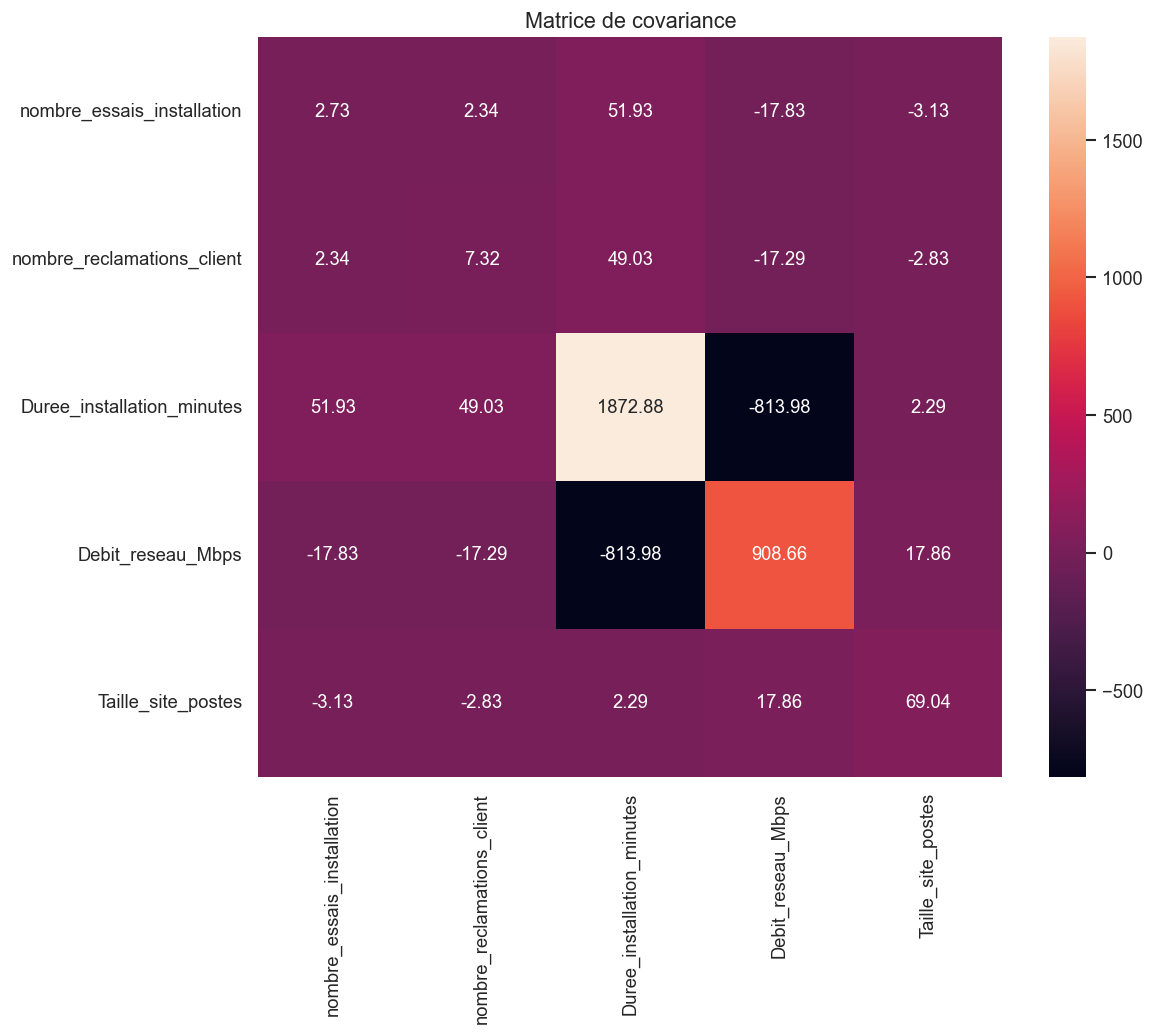

In [22]:
plt.figure(figsize=(10,8))
sns.heatmap(cov, annot=True, fmt=".2f")
plt.title("Matrice de covariance")
plt.show()

In [23]:
df.columns

Index(['Nom_produit', 'version_produit', 'date_installation', 'Gouvernorat',
       'Id_Client', 'Type_client', 'Systeme_exploitation_poste',
       'installation_reussie', 'nombre_essais_installation',
       'client_a_reclame', 'nombre_reclamations_client', 'client_satisfait',
       'Remarques', 'Technicien_ID', 'Duree_installation_minutes',
       'Debit_reseau_Mbps', 'Taille_site_postes', 'Mode_installation',
       'Tentative_installation_weekend', 'Version_precedente'],
      dtype='str')

### 3.7 Coefficient de corrélation

In [24]:
coeff_corr = df_num.corr(method='pearson')
coeff_corr

,nombre_essais_installation,nombre_reclamations_client,Duree_installation_minutes,Debit_reseau_Mbps,Taille_site_postes
nombre_essais_installation,1.000000,0.524122,0.726458,-0.358160,-0.228042
nombre_reclamations_client,0.524122,1.000000,0.418772,-0.212054,-0.125876
Duree_installation_minutes,0.726458,0.418772,1.000000,-0.623966,0.006378
Debit_reseau_Mbps,-0.358160,-0.212054,-0.623966,1.000000,0.071307
Taille_site_postes,-0.228042,-0.125876,0.006378,0.071307,1.000000


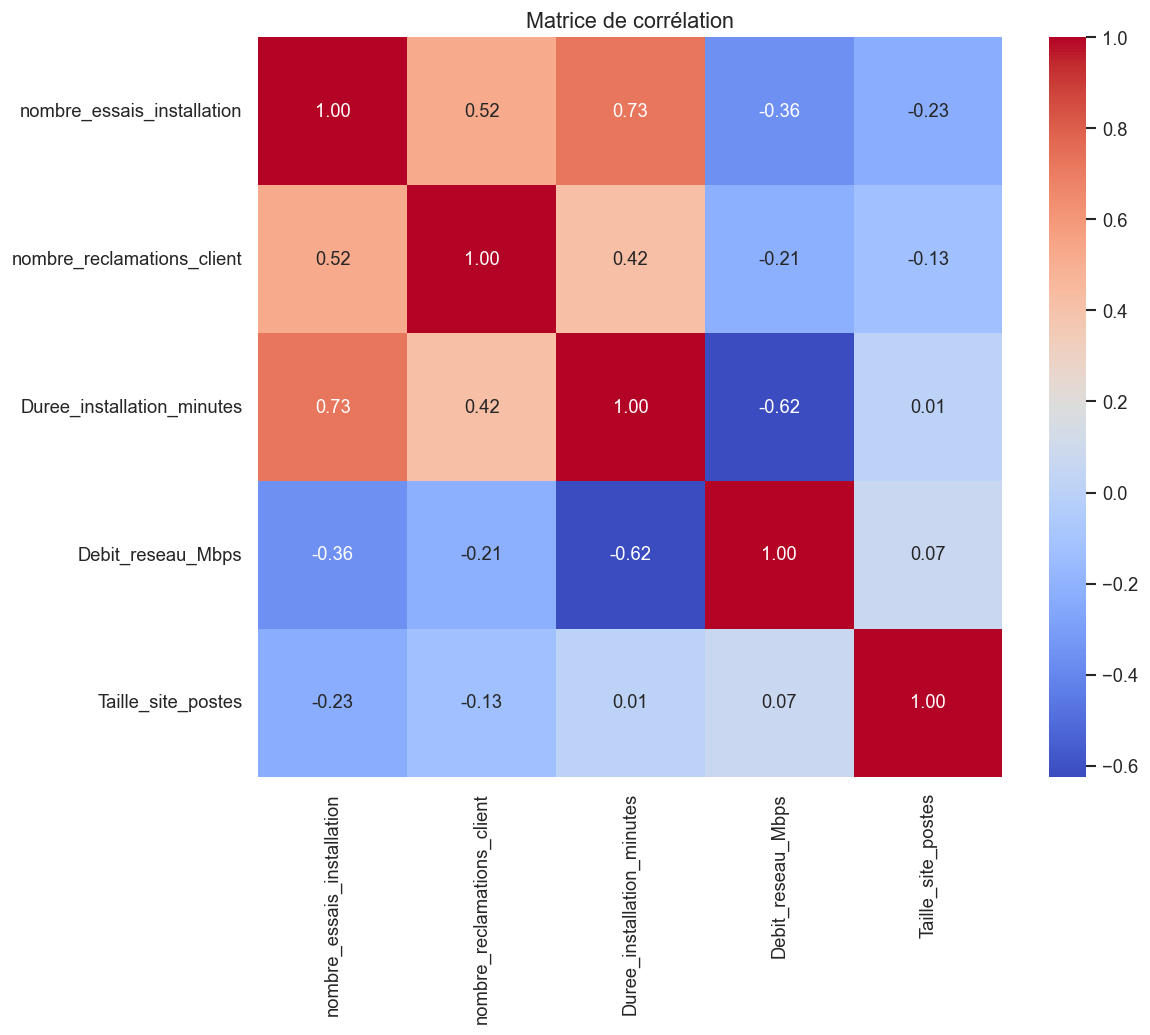

In [25]:
plt.figure(figsize=(10,8))
sns.heatmap(coeff_corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Matrice de corrélation")
plt.show()

### 3.6 Detection des Valeurs Aberrantes :

> *méthode 1* : visualisation

<Axes: xlabel='nombre_reclamations_client'>

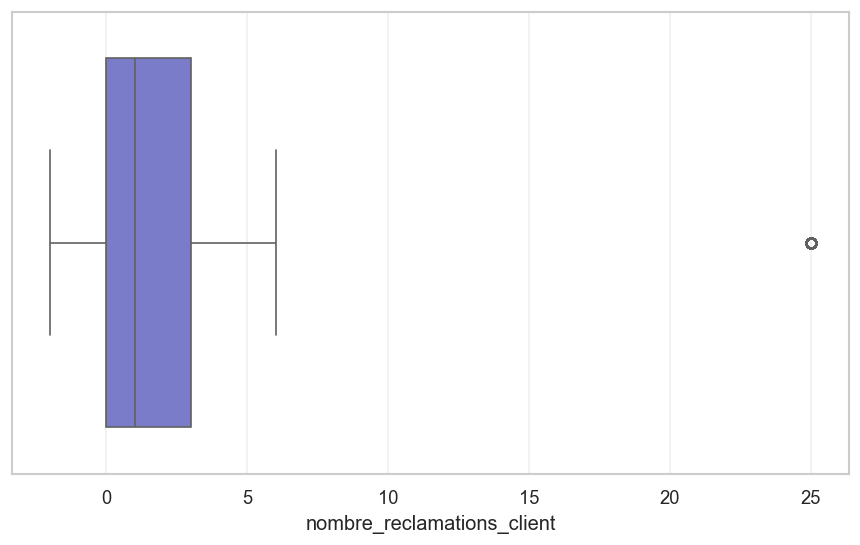

In [26]:
sns.boxplot(x=df['nombre_reclamations_client']) 

> *méthode 2* : IQR

In [27]:
Q1 = df['nombre_reclamations_client'].quantile(0.25)
Q3 = df['nombre_reclamations_client'].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df = df[(df['nombre_reclamations_client'] > lower) & (df['nombre_reclamations_client'] < upper)]

print(Q1, Q3, IQR)


0.0 3.0 3.0


la methode d'interquartile ne détecte pas les valeurs négatives proches comme -2 car la marge de confiance est [-3.5,8.5] qui est une valeur abherente comme `nombre_reclamations_client` ne peut pas etre négatif , donc il  faut supprimer cette valeur et la valeur 25 detecter par IQR.

<Axes: xlabel='Debit_reseau_Mbps'>

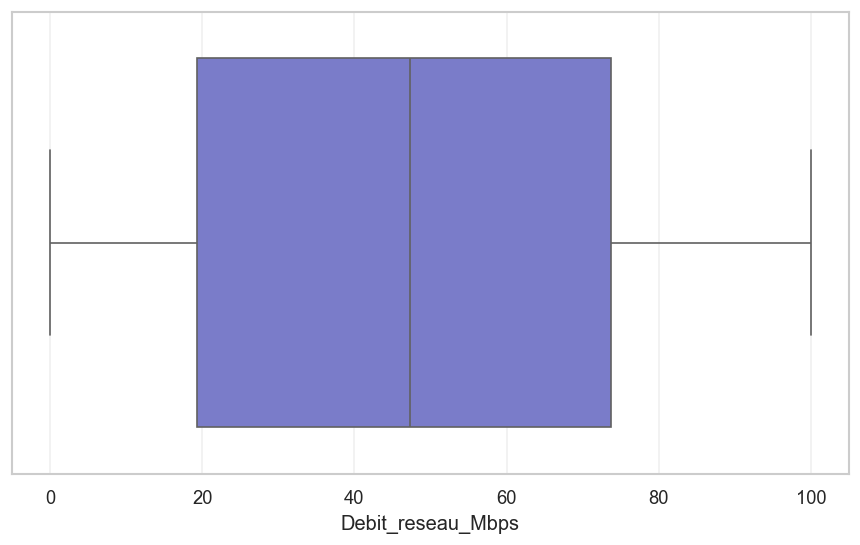

In [28]:
sns.boxplot(x=df['Debit_reseau_Mbps']) 

In [29]:
Q1 = df['Debit_reseau_Mbps'].quantile(0.25)
Q3 = df['Debit_reseau_Mbps'].quantile(0.75)
IQR = Q3 - Q1
outliers = df[(df['Debit_reseau_Mbps'] < Q1 - 1.5 * IQR) | (df['Debit_reseau_Mbps'] > Q3 + 1.5 * IQR)]
print(outliers["Debit_reseau_Mbps"].value_counts())
print(Q1, Q3, IQR)

Series([], Name: count, dtype: int64)
19.365000000000002 73.66 54.294999999999995


<Axes: xlabel='Duree_installation_minutes'>

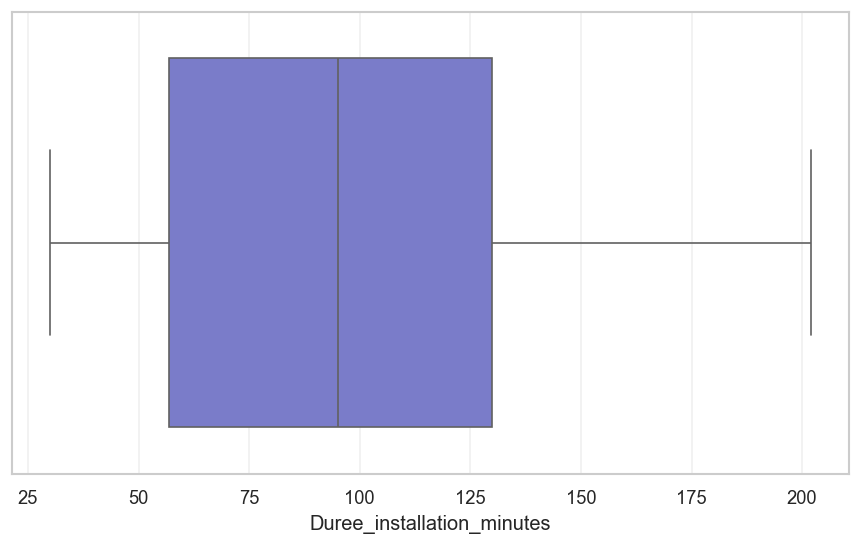

In [30]:
sns.boxplot(x=df['Duree_installation_minutes']) 

Il n y a pas de valeurs aberrantes dans les colonnes `Debit_reseau_Mbps` et `Duree_installation_minutes`

<Axes: xlabel='date_installation'>

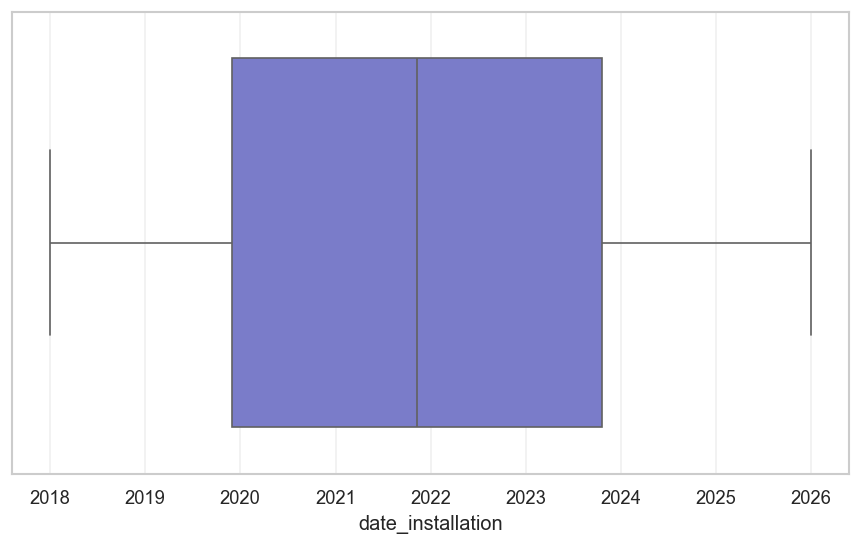

In [31]:
sns.boxplot(x=df['date_installation']) 

In [32]:
Q1 = df['date_installation'].quantile(0.25)
Q3 = df['date_installation'].quantile(0.75)
IQR = Q3 - Q1
df = df[(df['date_installation'] > Q1 - 1.5 * IQR) & (df['date_installation'] < Q3 + 1.5 * IQR)]
print(df["date_installation"].value_counts())
print(Q1, Q3, IQR)

date_installation
2020-11-09    14
2022-07-16    14
2024-06-06    14
2019-12-26    13
2019-06-12    13
              ..
2018-04-27     1
2024-12-05     1
2018-04-06     1
2025-01-09     1
2018-09-28     1
Name: count, Length: 2895, dtype: int64
2019-12-01 12:00:00 2023-10-19 00:00:00 1417 days 12:00:00


la méthode IQR à détecter une valeur aberrente la data 2032 qu'il faut la supprimer 

> *Méthode 3* : Z-score

* distribution normale ou non :

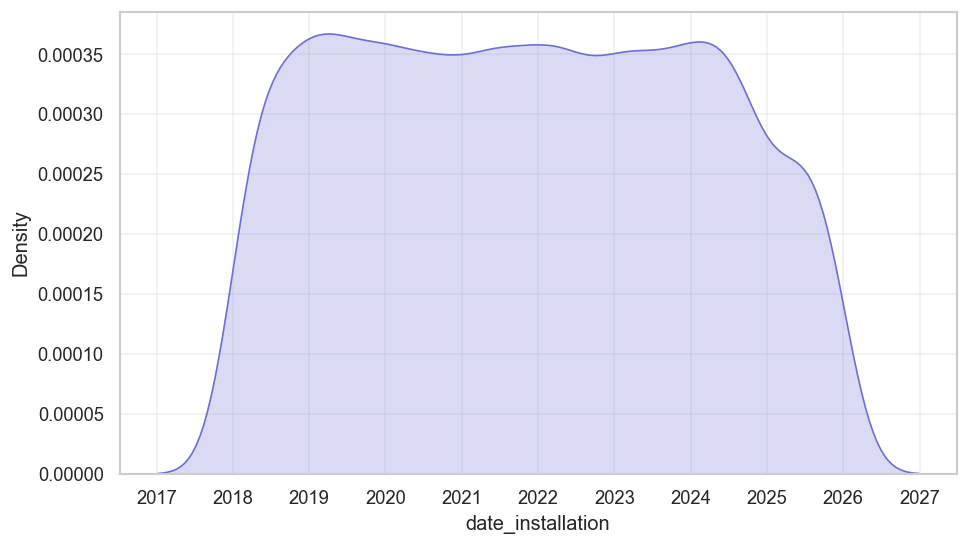

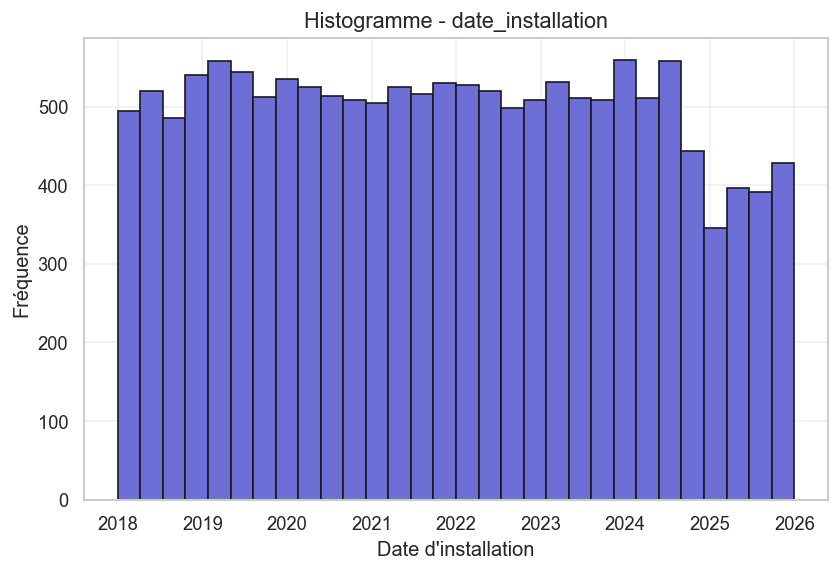

In [33]:
sns.kdeplot(df['date_installation'], fill=True)

plt.figure(figsize=(8,5))
plt.hist(df["date_installation"], bins=30, edgecolor='k')
plt.title("Histogramme - date_installation")
plt.xlabel("Date d'installation")
plt.ylabel("Fréquence")
plt.show()

## 4. Préparation des données

### 4.1 Nettoyage des données

* Nettoyage des valeurs abérrantes :

In [34]:
df = df[df["nombre_reclamations_client"]!=-2]

* Correction de l'incohérence des données dans `Systeme_exploitation_poste` :

In [35]:
df['Systeme_exploitation_poste'] = df['Systeme_exploitation_poste'].replace(
    ['win10', 'Win 10', 'Win10'],'Win10')

* Nettoyage des valeurs nulles:

si le porcentage de valeur manquante est inferieur à 5% alors on supprime les lignes avec des valeurs manquantes sinon on impute

In [36]:
#df = df.dropna(subset=["Id_Client"])
threshold = len(df) * 0.05
cols_to_drop = df.columns[(df.isna().sum() <= threshold) & (df.isna().sum() > 0)]
print(cols_to_drop)
df.dropna(subset=cols_to_drop, inplace=True )

Index(['Id_Client', 'installation_reussie'], dtype='str')


In [37]:
df["Remarques"].isna().sum() / len(df) * 100

np.float64(46.30854366311243)

on a 12% > a 5% d'ou on peut pas supprimer il faut bien remplacer les valeurs manquantes

### 4.2 Imputation des valeurs manquantes basée sur l’analyse statistique

### 4.2.1 Analyse des relations entre variables

* Dependance entre la variable `Remarques` et les variables qualitatives :

In [38]:
cat_cols = [
    'Nom_produit', 'Gouvernorat', 'Type_client',
    'Systeme_exploitation_poste', 'client_a_reclame',
    'client_satisfait', 'Technicien_ID',
    'Mode_installation', 'Tentative_installation_weekend',
    'version_produit','Version_precedente', 'installation_reussie'
]

In [39]:
results_chi2 = []

for col in cat_cols:
    ct = pd.crosstab(df[col], df["Remarques"])
    
    chi2, p, dof, Et = chi2_contingency(ct)
    
    # condition
    valid = (Et >= 5).all()
    
    results_chi2.append({
        "variable": col,
        "p_value": p,
        "dependence": p < 0.05,
        "condition_ok": valid
    })

pd.DataFrame(results_chi2).sort_values("p_value")

,variable,p_value,dependence,condition_ok
9,version_produit,0.000000e+00,True,True
2,Type_client,1.324060e-45,True,True
3,Systeme_exploitation_poste,7.972120e-36,True,False
1,Gouvernorat,9.648997e-15,True,True
7,Mode_installation,1.065668e-11,True,True
0,Nom_produit,2.177055e-10,True,True
11,installation_reussie,1.475186e-01,False,True
6,Technicien_ID,3.032060e-01,False,True
8,Tentative_installation_weekend,3.362884e-01,False,True
4,client_a_reclame,3.578390e-01,False,False


- dependance avec `version_produit`, `Type_client`, `Gouvernorat`, `Mode_installation` et `Nom_produit` 
- test khi deux ne marche pas sur Systeme_exploitation_poste il faut faire un autre test
- explication mathématiques du khi deux 

cas de `Nom_produit`:

In [40]:
table = pd.crosstab(df['Nom_produit'], df['Remarques'])
chi2, p, _, _ = chi2_contingency(table)
print(p)

2.1770547205683125e-10


- 0.02 < 0.05 donc il y a dependence entre les deux variables 
- on constate qu'il ya une dependence siginificative entre les deux variables `Nom_produit` et `Remarques` d'ou l'idee dimputer selon le nom de porduit est possible

    Cas 1 : manque espace disque

In [41]:
pd.crosstab(df['Nom_produit'], df['Remarques'], normalize='index')

Remarques,Problème adressage ip,connexion serveur lente,erreur configuration poste,manque espace disque,poste obsolète,problème réseau,version incompatible
Nom_produit,,,,,,,
GRB,0.136016,0.107489,0.099338,0.089149,0.095262,0.097809,0.374936
INSAF,0.132018,0.111786,0.109762,0.109256,0.098128,0.085483,0.353566
MADANIA,0.148574,0.103052,0.109555,0.096048,0.106553,0.097049,0.339170
MAKATIB,0.124442,0.089737,0.096678,0.164601,0.097174,0.083292,0.344075


- Pour la remarque manque espace disque est particulièrement élevé pour MAKATIB (0.149)
- Pour les autres remarques ils ont des valeurs proches entre produits donc on ne peut rien dire

In [42]:
pd.crosstab(df['Taille_site_postes'], df['Remarques'], normalize='index')

Remarques,Problème adressage ip,connexion serveur lente,erreur configuration poste,manque espace disque,poste obsolète,problème réseau,version incompatible
Taille_site_postes,,,,,,,
1,0.112994,0.135593,0.101695,0.101695,0.084746,0.129944,0.333333
2,0.120419,0.083770,0.083770,0.099476,0.109948,0.099476,0.403141
3,0.136612,0.120219,0.125683,0.092896,0.076503,0.114754,0.333333
4,0.154705,0.089314,0.102073,0.089314,0.094099,0.090909,0.379585
5,0.158155,0.093904,0.110379,0.085667,0.100494,0.085667,0.365733
6,0.125402,0.101286,0.122186,0.090032,0.107717,0.104502,0.348875
7,0.164319,0.101721,0.107981,0.095462,0.095462,0.086072,0.348983
8,0.177665,0.115059,0.091371,0.079526,0.103215,0.091371,0.341794
9,0.122034,0.120339,0.098305,0.098305,0.091525,0.083051,0.386441


- Quand `Taille_site_postes` supérieur ou égal à 26 le taux de `Remarques` manque espace disque augmente

> Regle 1 : imputer `Remarque` par manque espace disque quand le `Nom_produit` est MAKATIB et `Taille_site_postes` supérieur ou égal à 26 

    Cas 2 : version incompatible

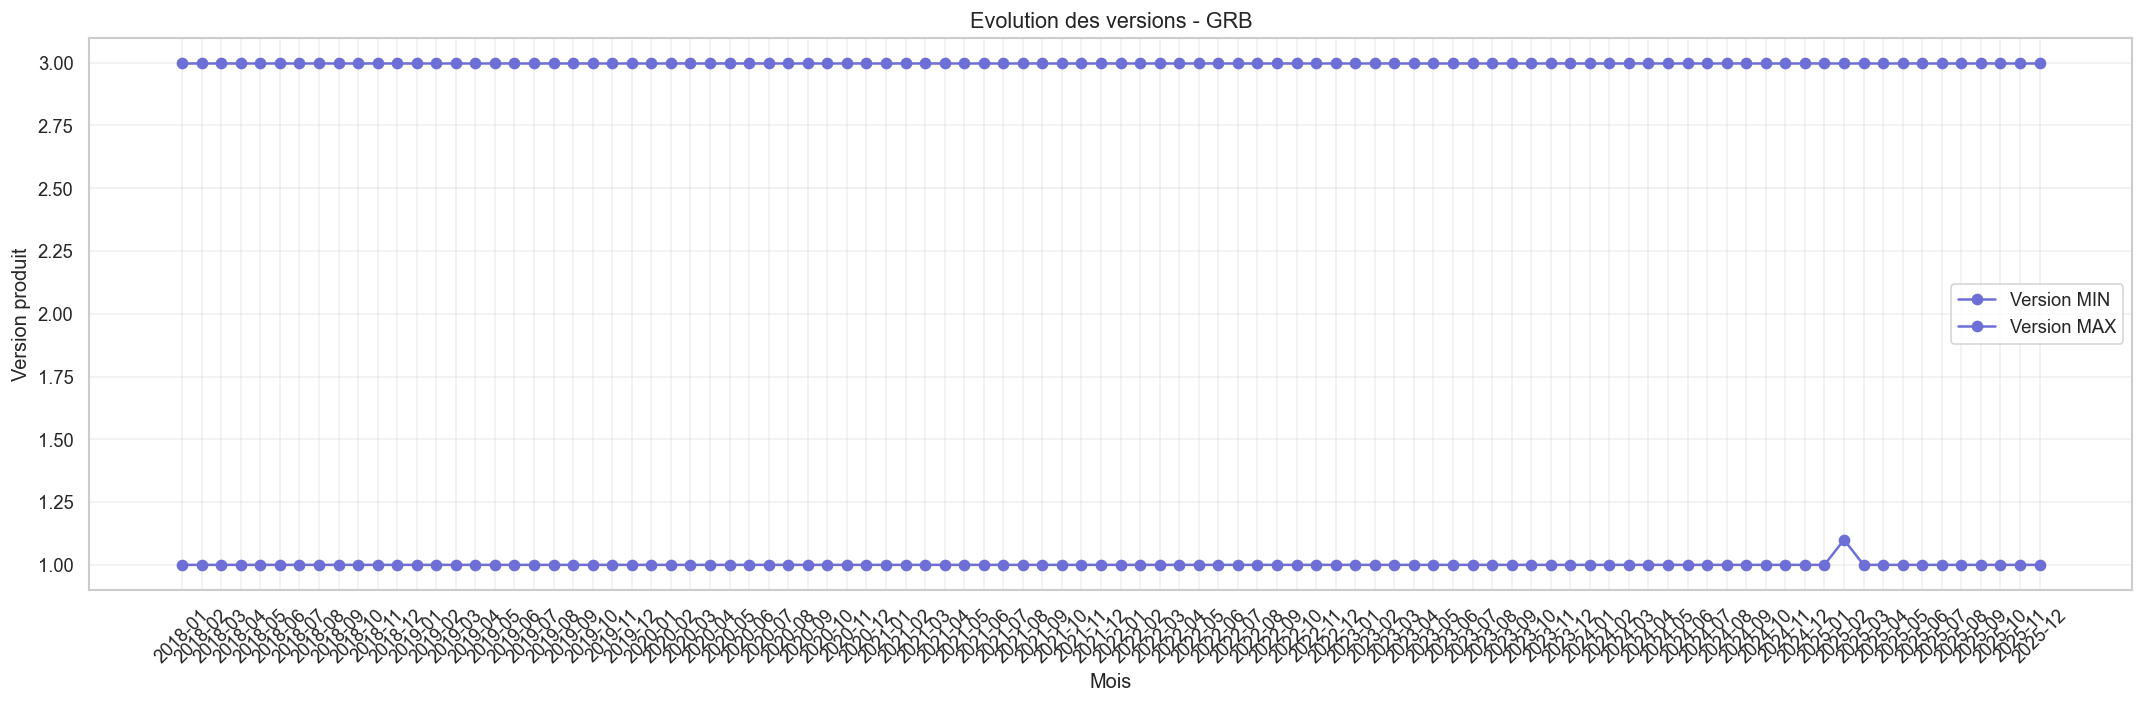

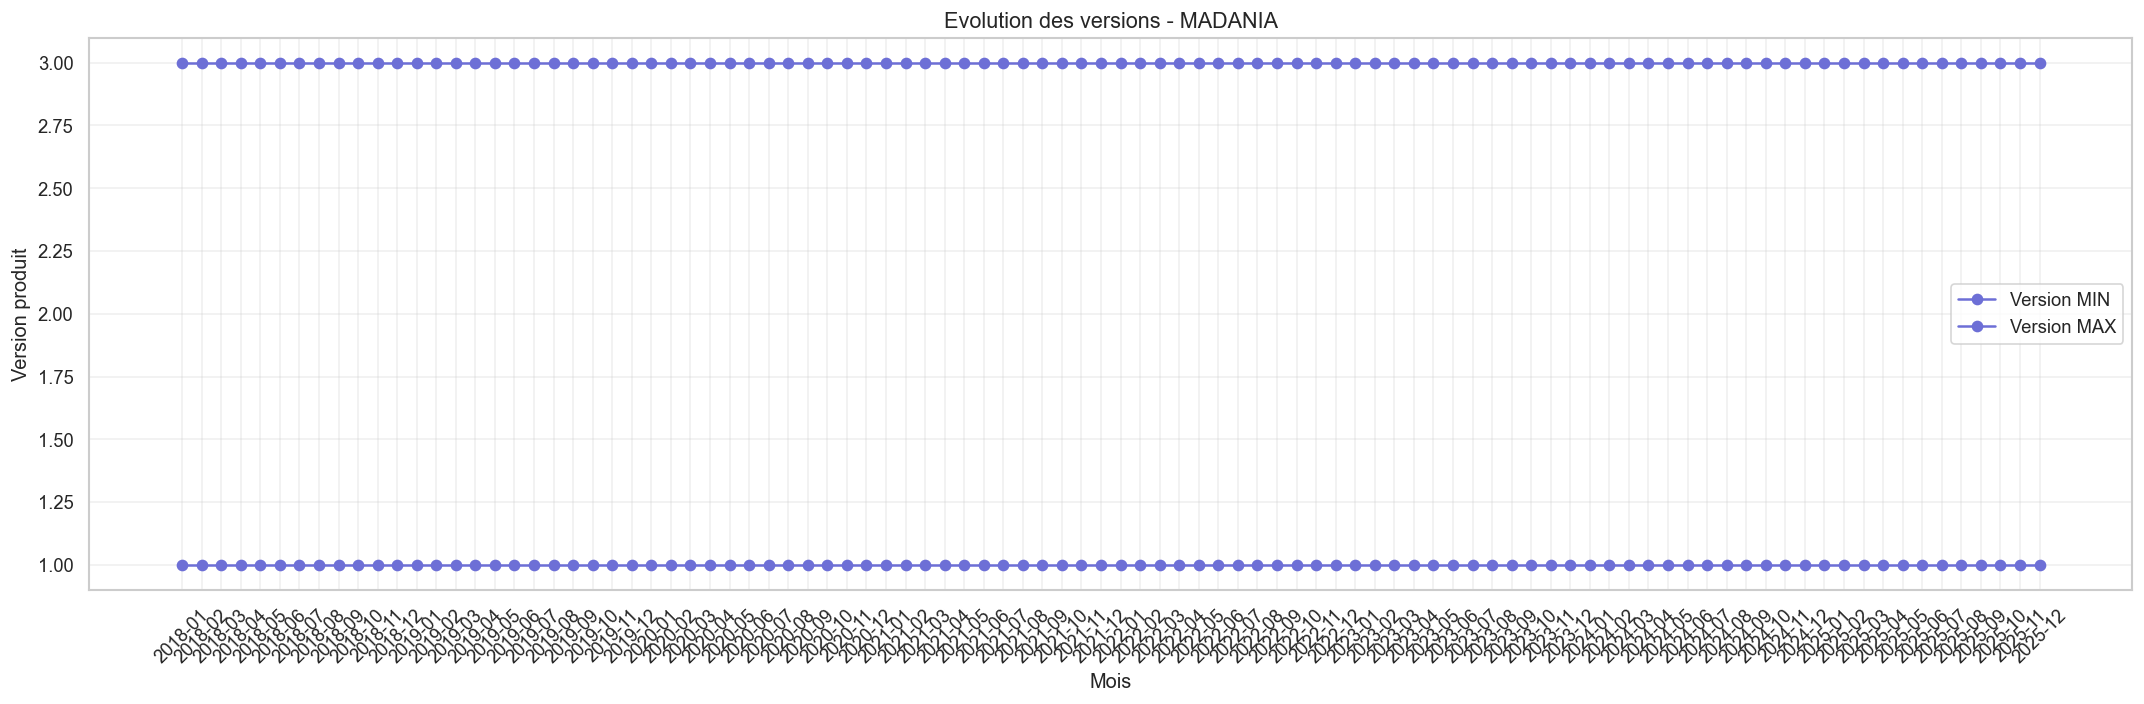

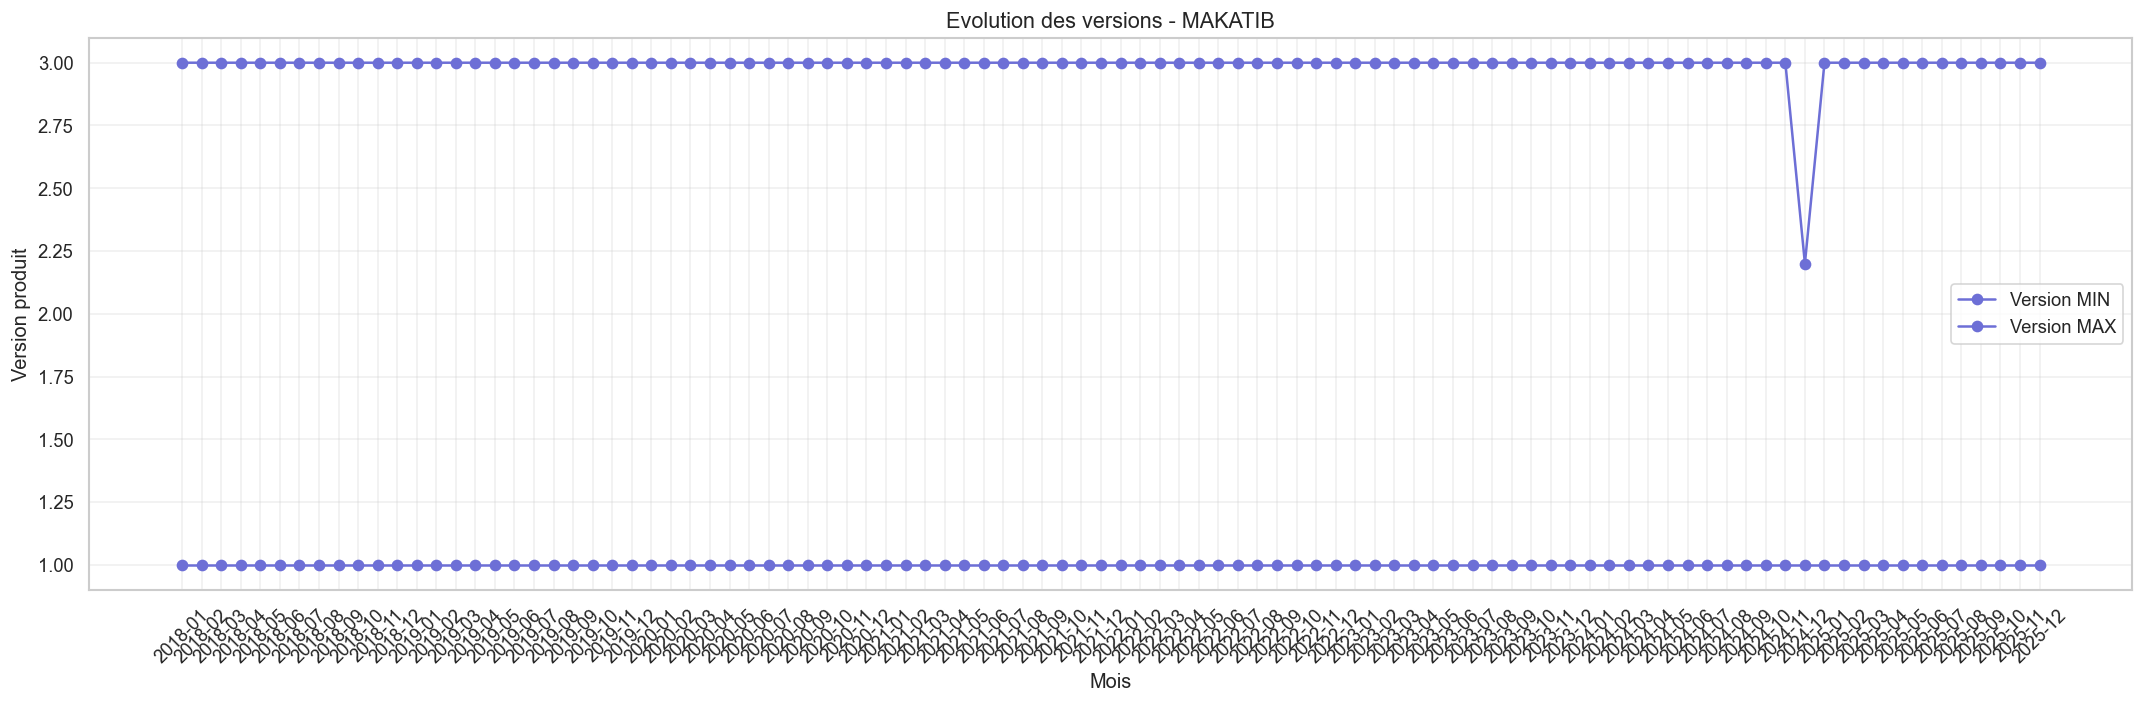

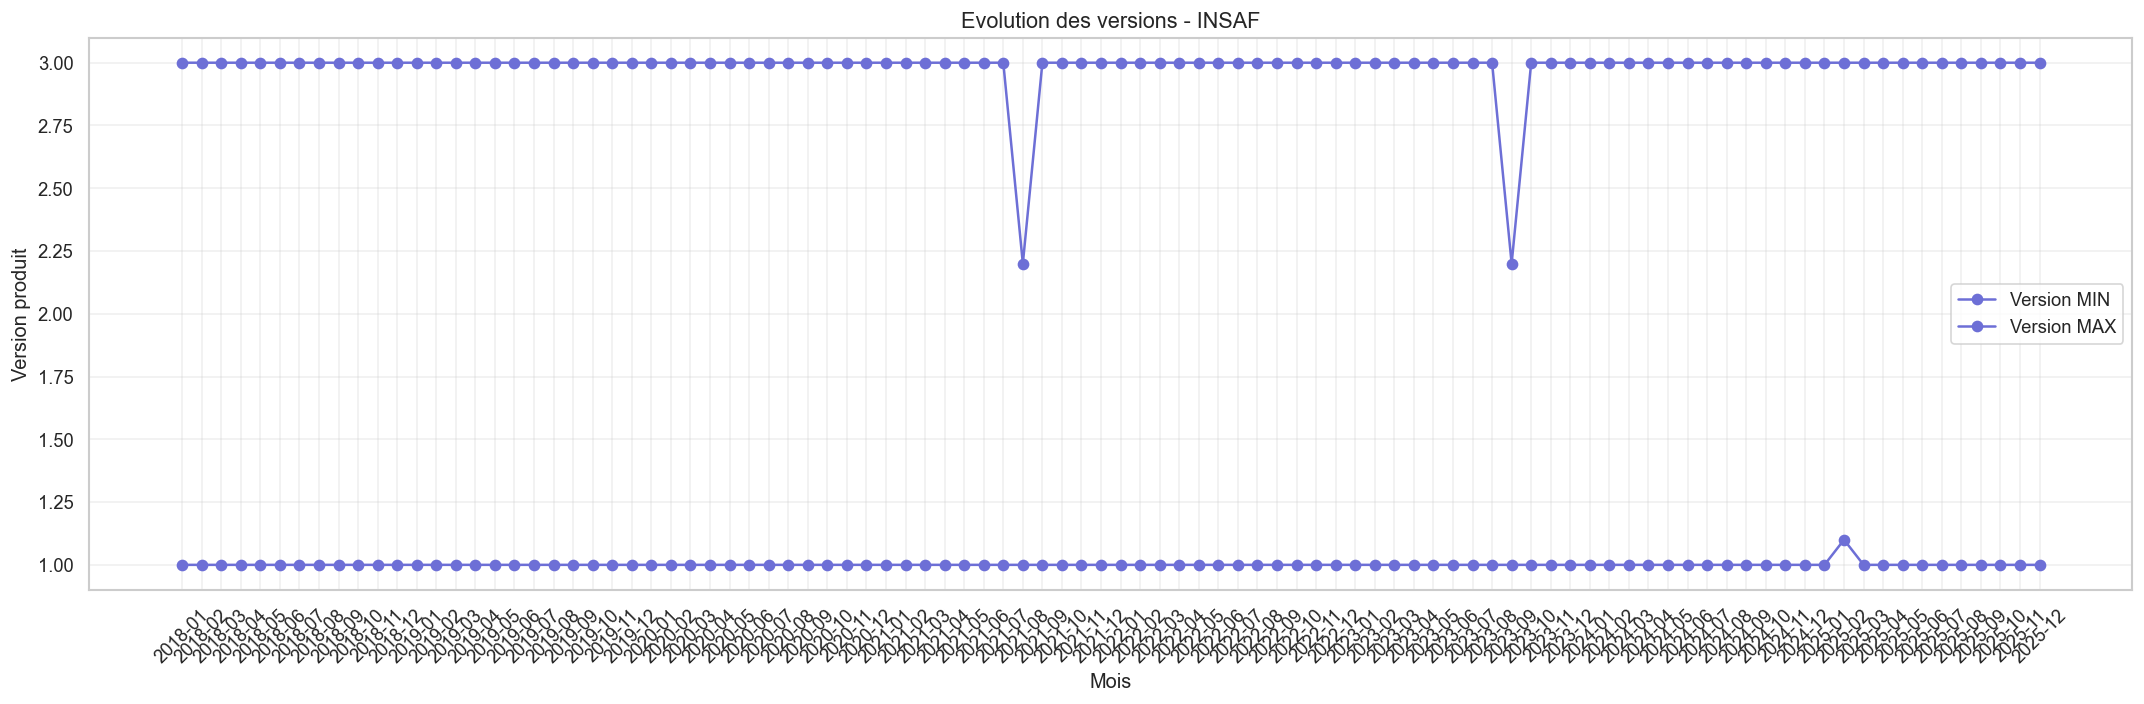

In [43]:
df = df.copy()

df['version_produit'] = pd.to_numeric(df['version_produit'], errors='coerce')
df['date_installation'] = pd.to_datetime(df['date_installation'])

df['mois'] = df['date_installation'].dt.to_period('M')

produits = ['GRB', 'MADANIA', 'MAKATIB', 'INSAF']

for produit in produits:
    
    subset = df[df['Nom_produit'] == produit]
    
    agg = subset.groupby('mois')['version_produit'].agg(['min', 'max']).reset_index()
    plt.figure(figsize=(18, 6))
    
    plt.plot(agg['mois'].astype(str), agg['min'], marker='o', label='Version MIN')
    plt.plot(agg['mois'].astype(str), agg['max'], marker='o', label='Version MAX')
    
    plt.title(f"Evolution des versions - {produit}")
    plt.xlabel("Mois")
    plt.ylabel("Version produit")
    plt.xticks(rotation=45)
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()
    
df = df.drop(columns="mois")
df['version_produit'] = df['version_produit'].astype(object)

- L'écart élevé entre les versions installées reflète une mauvaise synchronisation des mises à jour, ce qui peut engendrer des anomalies fonctionnelles, notamment des problèmes de compatibilité entre versions.

> Regle 2 : imputer `Remarque` par version incompatible quand il y a l'écart entre le min et le max des `version_produit` installer durant ce mois est superieur à 1

    Cas 3 : Problème adressage ip

In [44]:
pd.crosstab(df['Type_client'], df['Remarques'], normalize='index')

Remarques,Problème adressage ip,connexion serveur lente,erreur configuration poste,manque espace disque,poste obsolète,problème réseau,version incompatible
Type_client,,,,,,,
Collectivité locale,0.111513,0.122870,0.101704,0.092927,0.100155,0.102220,0.368611
EPA,0.108466,0.101058,0.107407,0.108995,0.100529,0.086243,0.387302
EPNA,0.219002,0.089311,0.103088,0.085986,0.099762,0.086461,0.316390
Ministère,0.095850,0.099802,0.103261,0.171937,0.096838,0.088933,0.343379


- La `Remarques` Problème adressage ip est particulièrement élevé pour EPNA (0.169)
- Pour les autres remarques ils ont des valeurs proches entre `Type_client` donc on ne peut rien dire

In [45]:
pd.crosstab(df['Mode_installation'], df['Remarques'], normalize='index')

Remarques,Problème adressage ip,connexion serveur lente,erreur configuration poste,manque espace disque,poste obsolète,problème réseau,version incompatible
Mode_installation,,,,,,,
Technicien_sur_site,0.106323,0.107343,0.113463,0.113972,0.103264,0.087965,0.367670
Télémaintenance,0.163361,0.098661,0.094447,0.116014,0.095439,0.093704,0.338374


- La `Remarques` Problème adressage ip est particulièrement élevé pour Télémaintenance (0.166898)
- Pour les autres remarques ils ont des valeurs proches entre `Mode_installation` donc on ne peut rien dire

In [46]:
pd.crosstab(df['Gouvernorat'], df['Remarques'], normalize='index')

Remarques,Problème adressage ip,connexion serveur lente,erreur configuration poste,manque espace disque,poste obsolète,problème réseau,version incompatible
Gouvernorat,,,,,,,
Ariana,0.107042,0.087324,0.104225,0.098592,0.092958,0.098592,0.411268
Ben Arous,0.138889,0.111111,0.119444,0.113889,0.108333,0.113889,0.294444
Bizerte,0.110738,0.130872,0.124161,0.117450,0.093960,0.087248,0.335570
Béja,0.179710,0.069565,0.098551,0.150725,0.113043,0.066667,0.321739
Gabès,0.105882,0.120588,0.091176,0.108824,0.102941,0.079412,0.391176
Gafsa,0.225705,0.062696,0.075235,0.075235,0.097179,0.090909,0.373041
Jendouba,0.227273,0.078788,0.072727,0.090909,0.112121,0.090909,0.327273
Kairouan,0.134670,0.106017,0.128940,0.134670,0.074499,0.114613,0.306590
Kasserine,0.198113,0.103774,0.056604,0.103774,0.106918,0.066038,0.364780


- La `Remarques` Problème adressage ip est particulièrement élevé pour Gafsa, Jendouba, Kasserine, Médenine, Tataouine (entre 0.2 et 0.24)
- La `Remarques` poste obsolète est particulièrement élevé pour Gafsa, Jendouba, Kasserine, Médenine, Tataouine
- Pour les autres remarques ils ont des valeurs proches entre `Gouvernorat` donc on ne peut rien dire

> Regle 3 : imputer `Remarque` par Problème adressage ip quand `Type_client` EPNA, `Mode_installation` Télémaintenance et `Gouvernorat` appartient à {Gafsa, Jendouba, Kasserine, Médenine, Tataouine}

    Cas 4 : erreur configuration poste

In [47]:
pd.crosstab(df['Systeme_exploitation_poste'], df['Remarques'], normalize='index')

Remarques,Problème adressage ip,connexion serveur lente,erreur configuration poste,manque espace disque,poste obsolète,problème réseau,version incompatible
Systeme_exploitation_poste,,,,,,,
Unknown,0.000000,0.000000,0.812500,0.000000,0.156250,0.000000,0.031250
Win10,0.128397,0.095595,0.102156,0.122774,0.091846,0.103093,0.356139
Win11,0.144527,0.111583,0.099894,0.105207,0.111583,0.091392,0.335813
Win7,0.116255,0.101852,0.111111,0.137860,0.120370,0.073045,0.339506
Win8,0.141404,0.090539,0.091556,0.116989,0.090539,0.098678,0.370295
Windows 2008 Server,0.143447,0.106295,0.087719,0.140351,0.091847,0.084623,0.345717
Windows 2012 Server,0.132632,0.105263,0.100000,0.113684,0.087368,0.091579,0.369474
Windows server 2016,0.134615,0.105030,0.076923,0.094675,0.099112,0.096154,0.393491
Windows server 2019,0.157025,0.104132,0.105785,0.094215,0.099174,0.084298,0.355372


- Les `Remarques` erreur configuration est particulièrement élevé pour Unknown et WindowsXP
- Pour les autres remarques ils ont des valeurs proches entre `Systeme_exploitation_poste` donc on ne peut rien dire

In [48]:
pd.crosstab(df['version_produit'], df['Remarques'], normalize='index')

Remarques,Problème adressage ip,connexion serveur lente,erreur configuration poste,manque espace disque,poste obsolète,problème réseau,version incompatible
version_produit,,,,,,,
1.0,0.097978,0.038880,0.056765,0.076205,0.047434,0.041213,0.641524
1.1,0.102857,0.066939,0.075918,0.075102,0.057143,0.052245,0.569796
1.2,0.090129,0.072103,0.065236,0.067811,0.066953,0.054077,0.583691
2.0,0.180492,0.161349,0.131267,0.133090,0.144941,0.113947,0.134913
2.1,0.164522,0.152574,0.140625,0.156250,0.121324,0.119485,0.145221
2.2,0.167297,0.128544,0.137996,0.160681,0.145558,0.123819,0.136106
3.0,0.159113,0.119576,0.135969,0.154291,0.131148,0.151398,0.148505


- Les `Remarques` erreur configuration et poste obsolète sont particulièrement élevé pour `version_produit`supérieur ou égal à 2.0
- Pour les autres remarques ils ont des valeurs proches entre `version_produit` donc on ne peut rien dire

> Regle 4 : imputer `Remarque` par erreur configuration poste quand `Systeme_exploitation_poste` est Unkown ou WindowsXP et `version_produit`supérieur ou égal à 2.0

    Cas 5 : poste obsolète

> Regle 5 : imputer `Remarque` par poste obsolète quand `version_produit`supérieur ou égal à 2.0 et `Gouvernorat` appartient à {Gafsa, Jendouba, Kasserine, Médenine, Tataouine}

* Dependanc entre la variable `Remarques` et les variables qualitatives :

In [49]:
num_cols = [
    'nombre_essais_installation',
    'nombre_reclamations_client', 'Duree_installation_minutes',
    'Debit_reseau_Mbps', 'Taille_site_postes'
]

In [50]:
X = df[num_cols].astype(float)
le = LabelEncoder()
y = le.fit_transform(df["Remarques"].astype(str))
mi = mutual_info_classif(X, y, random_state=0)
mi_results = pd.DataFrame({
    "Variable": num_cols,
    "Mutual Information": mi
}).sort_values(by="Mutual Information", ascending=False)

print(mi_results)

                     Variable  Mutual Information
0  nombre_essais_installation            0.425757
1  nombre_reclamations_client            0.394711
2  Duree_installation_minutes            0.337888
3           Debit_reseau_Mbps            0.285617
4          Taille_site_postes            0.052434


- L’information mutuelle obtenue (0.226) indique que le débit réseau contient une information statistiquement significative sur les remarques, mais cette dépendance est partielle et probablement concentrée sur certaines remarques car la répartiton est déséquilibrée
- Pour les autres variable l'information mutuelle obtenue est proche de 0 ce qui signifie qu'il n y a pas de dépendance avec `Remarques`

In [51]:
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import LabelEncoder

# X
X = df[["Debit_reseau_Mbps"]].astype(float)

# y
le = LabelEncoder()
y = le.fit_transform(df["Remarques"].astype(str))

# MI
mi = mutual_info_classif(X, y)

print(mi)

[0.2841401]


    Cas 6 : connexion serveur lente et problème réseau

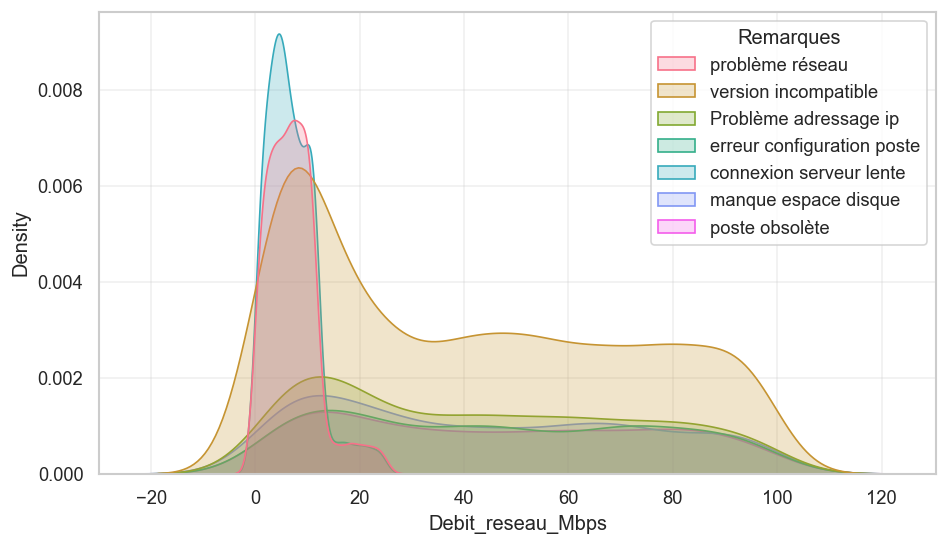

In [52]:
sns.kdeplot(data=df, x="Debit_reseau_Mbps", hue="Remarques", fill=True)
plt.show()

<Axes: xlabel='Remarques', ylabel='Debit_reseau_Mbps'>

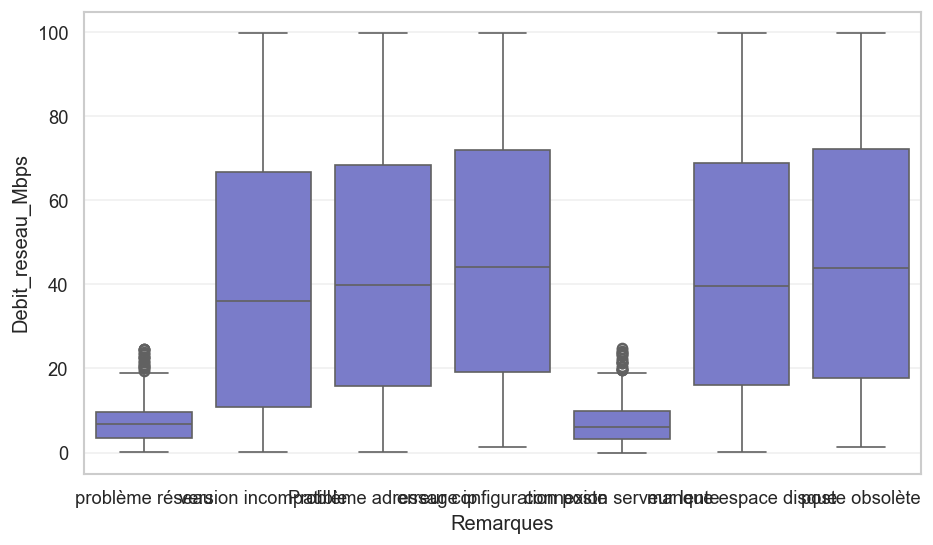

In [53]:
import seaborn as sns

sns.boxplot(x="Remarques", y="Debit_reseau_Mbps", data=df)

On remarque que le débit réseau influence surtout les problèmes liés directement à la connectivité comme `connexion serveur lente` et `problème réseau`. Les autres types de remarques ne semblent pas dépendre du débit.

on constate qu'il ya une dependence siginificative entre les deux variables `Debit_reseau_Mbps` et `Remarques` d'ou l'idee dimputer selon le `Debit_reseau_Mbps` est possible

In [54]:
df.groupby("Remarques")["Debit_reseau_Mbps"].mean()

Remarques
Problème adressage ip         42.902835
connexion serveur lente        6.841221
erreur configuration poste    46.167240
manque espace disque          43.387224
poste obsolète                45.958785
problème réseau                7.086791
version incompatible          40.443805
Name: Debit_reseau_Mbps, dtype: float64

> Regle 6 : imputer `Remarque` par connexion serveur lente ou problème réseau quand `Debit_reseau_Mbps` est inférieur ou égal à 6

### 4.2.2 Nettoyage des valeurs manquantes dans la colonne `Remarques`

In [55]:
import numpy as np

mask_missing = df["Remarques"].isna()

# -------------------------
# Règle 0 (TA CONDITION)
# -------------------------
mask_ok = (
    (df["installation_reussie"] == "oui") &
    (df["client_satisfait"] == "oui")
)

df.loc[mask_ok, "Remarques"] = "Aucune"

# -------------------------
# Règle 1
# -------------------------
df.loc[
    mask_missing &
    (df["Nom_produit"] == "MAKATIB") &
    (df["Taille_site_postes"] >= 26),
    "Remarques"
] = "manque espace disque"

# -------------------------
# Règle 2
# -------------------------
df.loc[
    mask_missing &
    (df.groupby(df["date_installation"].dt.to_period("M"))["version_produit"]
        .transform(lambda x: x.max() - x.min()) > 1),
    "Remarques"
] = "version incompatible"

# -------------------------
# Règle 3
# -------------------------
gouvernorats_risque = ["Gafsa", "Jendouba", "Kasserine", "Médenine", "Tataouine"]

df.loc[
    mask_missing &
    (df["Type_client"] == "EPNA") &
    (df["Mode_installation"] == "Télémaintenance") &
    (df["Gouvernorat"].isin(gouvernorats_risque)),
    "Remarques"
] = "Problème adressage ip"

# -------------------------
# Règle 4
# -------------------------
df.loc[
    mask_missing &
    (df["Systeme_exploitation_poste"].isin(["Unknown", "WindowsXP"])) &
    (df["version_produit"] >= 2.0),
    "Remarques"
] = "erreur configuration poste"

# -------------------------
# Règle 5
# -------------------------
df.loc[
    mask_missing &
    (df["version_produit"] >= 2.0) &
    (df["Gouvernorat"].isin(gouvernorats_risque)),
    "Remarques"
] = "poste obsolète"

# -------------------------
# Règle 6
# -------------------------
mask = mask_missing & (df["Debit_reseau_Mbps"] <= 6)

df.loc[mask, "Remarques"] = np.random.choice(
    ["connexion serveur lente", "problème réseau"],
    size=mask.sum()
)

In [56]:
df.isna().sum()

Nom_produit                       0
version_produit                   0
date_installation                 0
Gouvernorat                       0
Id_Client                         0
Type_client                       0
Systeme_exploitation_poste        0
installation_reussie              0
nombre_essais_installation        0
client_a_reclame                  0
nombre_reclamations_client        0
client_satisfait                  0
Remarques                         0
Technicien_ID                     0
Duree_installation_minutes        0
Debit_reseau_Mbps                 0
Taille_site_postes                0
Mode_installation                 0
Tentative_installation_weekend    0
Version_precedente                0
dtype: int64

* Remplacer Unknown par WindowsXP dans `Systeme_exploitation_poste` :

In [57]:
df["Systeme_exploitation_poste"] = df["Systeme_exploitation_poste"].replace("Unknown","WindowsXP")

In [58]:
df["Systeme_exploitation_poste"].value_counts()

Systeme_exploitation_poste
Win10                  2362
Win11                  2271
Windows server 2022    1936
Windows server 2019    1925
Windows server 2016    1904
Win8                   1085
Win7                   1074
Windows 2008 Server    1066
Windows 2012 Server    1065
WindowsXP               130
Name: count, dtype: int64

## 5. Feature engineering

### 5.1 Catégorisation des variables catégorielles

In [59]:
# taille du site :

def cat_taille(x):
    if x <= 10:
        return "petit"
    elif x <= 20:
        return "moyen"
    else:
        return "grand"

df["cat_taille"] = df["Taille_site_postes"].apply(cat_taille)

In [60]:
# Debit reseau :

def cat_debit(x):
    if x < 5:
        return "faible"
    elif x < 20:
        return "moyen"
    else:
        return "bon"

df["cat_debit"] = df["Debit_reseau_Mbps"].apply(cat_debit)

In [61]:
# zone d'urbanisation :

metropolitaine = [
    "Tunis", "Ariana", "Ben Arous", "Manouba",
    "Sfax", "Sousse", "Monastir", "Nabeul", "Bizerte"
]

mixte = [
    "Mahdia", "Kairouan", "Gabès", "Zaghouan",
    "Béja", "Siliana", "Le Kef", "Tozeur", "Gafsa"
]

rurale = [
    "Jendouba", "Kasserine", "Sidi Bouzid",
    "Médenine", "Tataouine", "Kébili"
]
def classify_region(x):
    if x in metropolitaine:
        return "metropolitaine"
    elif x in mixte:
        return "mixte"
    elif x in rurale:
        return "rurale"
    else:
        return "inconnu"

df["zone_urbanisation"] = df["Gouvernorat"].apply(classify_region)

### 5.2 Extraction et construction de variables

In [62]:
# Remarques :
df["pb_reseau"] = df["Remarques"].str.contains("réseau|connexion|serveur", case=False, na=False).astype(int)
df["pb_configuration"] = df["Remarques"].str.contains("configuration|adresse|ip", case=False, na=False).astype(int)
df["pb_materiel"] = df["Remarques"].str.contains("disque|poste|obsolète", case=False, na=False).astype(int)
df["pb_version"] = df["Remarques"].str.contains("version|incompatible", case=False, na=False).astype(int)
df["pb_aucun"] = df["Remarques"].str.contains("Aucun|Aucune", case=False, na=False).astype(int)

In [63]:
# variable temporelle :

df["annee"] = df["date_installation"].dt.year
df["jour_semaine"] = df["date_installation"].dt.dayofweek
df["mois"] = df["date_installation"].dt.to_period("M").astype(str)

In [64]:
# variable version :

df["upgrade"] = (df["version_produit"] == df["version_produit"].max()).astype("int")

In [65]:
# variable de satisfaction :

df["score_risque"] = (
    # réseau faible
    (df["Debit_reseau_Mbps"] < 5).astype(int) +

    # installation difficile
    (df["nombre_essais_installation"] > 2).astype(int) +

    # durée trop longue
    (df["Duree_installation_minutes"] > 120).astype(int) +

    # OS instable / ancien
    (df["Systeme_exploitation_poste"].str.contains("WindowsXP", case=False, na=False)).astype(int) +

    # produits historiquement problématiques (selon ton domaine)
    (df["Nom_produit"].isin(["GRB"])).astype(int) +

    # anciennes versions = plus de bugs
    (df["version_produit"].astype(str).str.contains("1\\.|2\\.|3\\.", na=False)).astype(int) +

    # taille site complexe
    (df["Taille_site_postes"] > 15).astype(int) +
    
    # gouvernorat
    (df["Gouvernorat"].isin(["Gafsa", "Jendouba", "Kasserine", "Médenine", "Tataouine"])).astype(int)
)

df["client_risque"] = (df["score_risque"] >= 3).astype(int)

### 5.3 Encodage des variables

In [66]:
# Encodage sur la dataframe qu'on va utiliser pour poduire des modeles fiables 

# Variables catégorielles binaires:
binary_cols = [
    "installation_reussie",
    "client_satisfait",
    "client_a_reclame",
    "Tentative_installation_weekend"
]

for col in binary_cols:
    df[col+'_encoded'] = df[col].map({"oui":1, "non":0})

In [67]:
# Version produit

df["version_produit_o"] = df["version_produit"]
df["version_produit_encoded"] = df.groupby("version_produit")["installation_reussie_encoded"].transform("mean")


In [68]:
# OS 

df["os_enc"] = df.groupby("Systeme_exploitation_poste")["installation_reussie_encoded"].transform("mean")

In [69]:
for col in ["Nom_produit", "Type_client", "Mode_installation","cat_taille", "cat_debit","zone_urbanisation"] : 
    df[col+"_o"] = df[col]

In [70]:
var_a_encoder = ["Nom_produit", "Type_client", "Mode_installation","cat_taille", "cat_debit","zone_urbanisation"]
df = pd.get_dummies(df, columns=var_a_encoder, drop_first=True)

 ## 6.Construction des KPI

### 6.1 Création du dataframe pour kpi

In [71]:
df_kpi = df.copy()
var_a_effacer =["Nom_produit", 'date_installation', 'Gouvernorat',
       'Id_Client', 'Type_client', 'Systeme_exploitation_poste',
       'client_a_reclame','Remarques', 'Technicien_ID',"version_produit",
       'Debit_reseau_Mbps', 'Taille_site_postes', 'Mode_installation',
       'Version_precedente',"cat_version", "cat_taille", "cat_debit", "zone_urbanisation",
       'score_risque', 'year',"installation_reussie","client_satisfait",
    "client_a_reclame","mois","Tentative_installation_weekend",
    "Nom_produit_o", "Type_client_o", "Mode_installation_o","cat_taille_o", "cat_debit_o","zone_urbanisation_o"]

df_kpi = df_kpi.drop(columns=var_a_effacer, errors='ignore')

In [72]:
df_kpi.columns

Index(['nombre_essais_installation', 'nombre_reclamations_client',
       'Duree_installation_minutes', 'pb_reseau', 'pb_configuration',
       'pb_materiel', 'pb_version', 'pb_aucun', 'annee', 'jour_semaine',
       'upgrade', 'client_risque', 'installation_reussie_encoded',
       'client_satisfait_encoded', 'client_a_reclame_encoded',
       'Tentative_installation_weekend_encoded', 'version_produit_o',
       'version_produit_encoded', 'os_enc', 'Nom_produit_INSAF',
       'Nom_produit_MADANIA', 'Nom_produit_MAKATIB', 'Type_client_EPA',
       'Type_client_EPNA', 'Type_client_Ministère',
       'Mode_installation_Télémaintenance', 'cat_taille_moyen',
       'cat_taille_petit', 'cat_debit_faible', 'cat_debit_moyen',
       'zone_urbanisation_mixte', 'zone_urbanisation_rurale'],
      dtype='str')

### 6.1 Matrice de corrélation : Relation entre les variables

In [73]:
coeff_corr = df_kpi.corr(method='pearson')

fig = px.imshow(
    coeff_corr,
    text_auto=".2f",
    color_continuous_scale="RdBu_r",
    zmin=-1, zmax=1,
    aspect="auto"
)

fig.update_layout(
    title="Matrice de corrélation interactive",
    width=1400,   
    height=1200   
)

fig.update_traces(
    hovertemplate="X: %{x}<br>Y: %{y}<br>Corr: %{z:.2f}<extra></extra>"
)

fig.show()

### 6.2 KPI globaux

In [74]:
kpi_global = {
    "nb_installations": len(df), 
    "taux_reussite": df["installation_reussie_encoded"].mean(),
    "taux_satisfaction": df["client_satisfait_encoded"].mean(),
    "taux_reclamation": df["nombre_reclamations_client"].mean(),
    "duree_moyenne": df["Duree_installation_minutes"].mean(),
    "nb_moyen_essais": df["nombre_essais_installation"].mean()
}
kpi_global

{'nb_installations': 14818,
 'taux_reussite': np.float64(0.4865029018760966),
 'taux_satisfaction': np.float64(0.43831826157376164),
 'taux_reclamation': np.float64(1.6541368605749764),
 'duree_moyenne': np.float64(94.56890268592252),
 'nb_moyen_essais': np.float64(3.52368740720745)}

### 5.1 PRODUIT vs OS & DURÉE

In [75]:
kpi_produit = df.groupby("Nom_produit_o").agg({
    "Duree_installation_minutes": "mean",
    "installation_reussie_encoded": "mean"
}).rename(columns={
    "Duree_installation_minutes": "temps_moyen",
    "installation_reussie_encoded": "taux_reussite"
})

print(kpi_produit.head())

               temps_moyen  taux_reussite
Nom_produit_o                            
GRB              89.326378       0.511503
INSAF            95.594757       0.482523
MADANIA          96.925946       0.475361
MAKATIB          96.486782       0.476368


In [76]:
fig = px.box(
    df,
    x="Nom_produit_o",
    y="Duree_installation_minutes",
    color="Nom_produit_o",
    title="Durée d'installation par produit"
)

fig.update_layout(xaxis_tickangle=-45)
fig.show()

In [77]:
import plotly.express as px
kpi_os = pd.crosstab(df["Nom_produit_o"], df["Systeme_exploitation_poste"])

fig = px.imshow(
    kpi_os,
    text_auto=True,
    color_continuous_scale="RdBu",
    title="Produit vs Système d'exploitation"
)

fig.update_layout(height=500)
fig.show()

### 5.2 VERSION vs REMARQUES

In [78]:
kpi_version = df.groupby("version_produit")["Remarques"].count().sort_values(ascending=False)
print(kpi_version)

version_produit
1.0    2245
1.1    2201
2.0    2121
1.2    2115
2.1    2073
2.2    2033
3.0    2030
Name: Remarques, dtype: int64


In [79]:
kpi_version = df.groupby("version_produit")["Remarques"].count().reset_index()

fig = px.bar(
    kpi_version,
    x="version_produit",
    y="Remarques",
    color="Remarques",
    title="Remarques par version produit"
)

fig.show()

### 5.3 TYPE CLIENT vs TAILLE SITE

In [80]:
kpi_client = df.groupby("Type_client_o")["Taille_site_postes"].mean()
print(kpi_client)

Type_client_o
Collectivité locale    10.359064
EPA                    11.574236
EPNA                   11.406101
Ministère              19.308783
Name: Taille_site_postes, dtype: float64


In [81]:
fig = px.box(
    df,
    x="Type_client_o",
    y="Taille_site_postes",
    color="Type_client_o",
    title="Taille des sites par type client"
)

fig.show()

### 5.4 SUCCÈS INSTALLATION

In [82]:
kpi_success = {
    "taux_reussite": df["installation_reussie_encoded"].mean(),
    "moyenne_essais": df["nombre_essais_installation"].mean(),
    "temps_moyen": df["Duree_installation_minutes"].mean(),
    "taux_satisfaction": df["client_satisfait_encoded"].mean()
}
kpi_success

{'taux_reussite': np.float64(0.4865029018760966),
 'moyenne_essais': np.float64(3.52368740720745),
 'temps_moyen': np.float64(94.56890268592252),
 'taux_satisfaction': np.float64(0.43831826157376164)}

In [83]:
import plotly.io as pio

df_grouped = df.groupby("installation_reussie")["nombre_essais_installation"].mean().reset_index()

fig = px.bar(
    df_grouped,
    x="installation_reussie",
    y="nombre_essais_installation",
    color="installation_reussie",
    color_discrete_map={0: "#e74c3c", 1: "#2ecc71"}
)

fig.show()

In [84]:
df_grouped2 = df.groupby("installation_reussie")["Duree_installation_minutes"].mean().reset_index()
df_grouped2
fig = px.bar(
    df_grouped2,
    x="installation_reussie",
    y="Duree_installation_minutes",
    color="installation_reussie",
    title="Durée vs Réussite"
)
fig.show()

In [85]:
df_grouped3 = df.groupby("installation_reussie")["client_satisfait_encoded"].mean().reset_index()

fig = px.bar(
    df_grouped3,
    x="installation_reussie",
    y="client_satisfait_encoded",
    color="installation_reussie",
    title="Réussite vs Satisfaction",
    barmode="group"
)
fig.show()

### 5.5 NOMBRE ESSAIS (EFFORT TECHNIQUE)

In [86]:
kpi_essais = df["nombre_essais_installation"].describe()
kpi_essais

count    14818.000000
mean         3.523687
std          1.657365
min          1.000000
25%          2.000000
50%          4.000000
75%          5.000000
max          5.000000
Name: nombre_essais_installation, dtype: float64

In [87]:
df_grouped4 = df.groupby("nombre_essais_installation")["Duree_installation_minutes"].mean().reset_index()
fig = px.bar(
    df_grouped4,
    x="nombre_essais_installation",
    y="Duree_installation_minutes",
    title="Essais vs Durée (avec satisfaction)"
)

fig.show()

In [88]:
df_grouped5 = df.groupby("client_satisfait")["nombre_essais_installation"].mean().reset_index()
fig = px.bar(
    df_grouped5,
    y="client_satisfait",
    x="nombre_essais_installation",
    title="Essais vs Satisfaction"
)
fig.show()

### 5.6 RÉCLAMATIONS CLIENT

In [89]:
kpi_reclamation = {
    "taux_reclamation": df["client_a_reclame_encoded"].mean(),
    "moyenne_reclamations": df["nombre_reclamations_client"].mean()
}

kpi_reclamation

{'taux_reclamation': np.float64(0.5834795518963423),
 'moyenne_reclamations': np.float64(1.6541368605749764)}

In [90]:
# Réclamation vs satisfaction
df_grouped6 = df.groupby("client_a_reclame")["client_satisfait_encoded"].mean().reset_index()
fig = px.bar(
    df_grouped6,
    x="client_a_reclame",
    y="client_satisfait_encoded",
    color="client_a_reclame",
    title="Impact des réclamations sur la satisfaction"
)

fig.show()

### 5.7 NOMBRE RÉCLAMATIONS

In [91]:
kpi_nb_reclam = df["nombre_reclamations_client"].describe()
print(kpi_nb_reclam)

count    14818.000000
mean         1.654137
std          1.897816
min          0.000000
25%          0.000000
50%          1.000000
75%          3.000000
max          6.000000
Name: nombre_reclamations_client, dtype: float64


In [92]:
fig = px.box(
    df,
    x="client_a_reclame",
    y="Duree_installation_minutes",
    color="client_a_reclame",
    title="Réclamation vs Durée"
)

fig.show()

### 5.8 SATISFACTION CLIENT

In [93]:
taux_satisfaction = df["client_satisfait_encoded"].mean()
print("Taux satisfaction:", taux_satisfaction)

Taux satisfaction: 0.43831826157376164


In [94]:
fig = px.box(
    df,
    x="client_satisfait",
    y="Duree_installation_minutes",
    color="client_satisfait",
    title="Satisfaction vs Durée"
)

fig.show()

### 5.81 KPI temporels

In [95]:
kpi_temporel = df.groupby('mois').agg({
    "installation_reussie_encoded": "mean",
    "client_satisfait_encoded": "mean",
    "nombre_reclamations_client": "mean",
    "nombre_essais_installation": "mean",
    "Duree_installation_minutes": "mean",
    "client_a_reclame_encoded": "mean"
}).reset_index()

kpi_temporel.head()

,mois,installation_reussie_encoded,client_satisfait_encoded,nombre_reclamations_client,nombre_essais_installation,Duree_installation_minutes,client_a_reclame_encoded
0,2018-01,0.513333,0.433333,1.660000,3.453333,96.186667,0.580000
1,2018-02,0.506579,0.480263,1.322368,3.375000,92.151316,0.552632
2,2018-03,0.513158,0.453947,1.677632,3.513158,92.677632,0.565789
3,2018-04,0.557823,0.476190,1.326531,3.380952,89.687075,0.551020
4,2018-05,0.500000,0.426829,1.786585,3.554878,97.103659,0.603659


In [96]:
import plotly.express as px

fig = px.line(
    kpi_temporel,
    x="mois",
    y="installation_reussie_encoded",
    markers=True,
    title="Évolution du taux de réussite"
)

fig.show()

In [97]:
fig = px.line(
    kpi_temporel,
    x="mois",
    y=["client_satisfait_encoded", "client_a_reclame_encoded"],
    markers=True,
    title="Satisfaction vs Réclamations dans le temps"
)

fig.show()

In [98]:
fig = px.line(
    kpi_temporel,
    x="mois",
    y="Duree_installation_minutes",
    markers=True,
    title="Évolution du temps d'installation"
)

fig.show()

In [99]:
fig = px.line(
    kpi_temporel,
    x="mois",
    y="nombre_essais_installation",
    markers=True,
    title="Évolution du nombre d'essais"
)

fig.show()

In [100]:
fig = px.line(
    kpi_temporel,
    x="mois",
    y="nombre_reclamations_client",
    markers=True,
    title="Évolution des réclamations"
)
fig.show()

In [101]:
fig = px.line(
    kpi_temporel,
    x="mois",
    y=["installation_reussie_encoded", "client_satisfait_encoded"],
    title="Drift qualité (réussite vs satisfaction)"
)

fig.show()

In [102]:
installations_temps = df.groupby("mois").size().reset_index(name="nombre_installations")
fig = px.line(
    installations_temps,
    x="mois",
    y="nombre_installations",
    markers=True,
    title="Nombre d'installations dans le temps"
)

fig.show()

- installation_reussie : Nom_produit(relation faible),version_produit(relation moyenne), Gouvernorat(relation tres faible) en relation avec Debit_reseau_Mbps(relation forte) et Remarques(relation forte) et Taille_site_postes(relation negative moyenne), Systeme_exploitation_poste(relation tres forte),Technicien_ID(relation positive moyenne), nombre_essais_installatio(relation négative tres forte), client_a_reclame(relation negative forte), nombre_reclamations_client(relation negative forte), client_satisfait(relation positive tres forte), Mode_installation(relation positive moyenne), Duree_installation_minutes(relation negative forte)

- client_satisfait : Nom_produit(relation faible), version_produit(relation faible),Remarques(relation negative forte), Debit_reseau_Mbps(relation positive moyenne), Mode_installation(relation faible), nombre_essais_installation(relation negative forte), Duree_installation_minutes(relation negative forte), installation_reussie(relation positive tres forte), client_a_reclame(relation negative tres forte), nombre_reclamations_client(relation negative tres forte)

- client_a_reclame : Nom_produit(relation faible), version_produit(relation moyenne), Systeme_exploitation_poste(relation positive moyenne/forte), Remarques(relation positive tres forte), Debit_reseau_Mbps(relation positive moyenne), nombre_essais_installation(relation positive tres forte), Duree_installation_minutes(relation positive forte), installation_reussie(relation negative tres forte),  nombre_reclamations_client(relation positive tres forte), client_satisfait(relation negative tres forte)

- Duree_installation_minutes : Nom_produit(relation forte pour makatib app 20gb), version_produit(relation positive faible/moyenne), Gouvernorat(relaion forte), Systeme_exploitation_poste(relaion tres forte), Remarques(relation moyenne), Debit_reseau_Mbps(relation negative tres forte), Mode_installation(relation moyenne), nombre_essais_installation(relation positive forte),Tentative_installation_weekend(relation moyenne), client_satisfait(relation négative moyenne), client_a_reclame(relation positive forte), nombre_reclamations_client(relation positive moyenne)

- nombre_essais_installation : Nom_produit(relation positive moyenne), version_produit(relation positive moyenne), Gouvernorat(relation forte), Systeme_exploitation_poste(relation positive forte), Remarques(relation positive tres forte), Debit_reseau_Mbps(relation negative forte), Mode_installation(relation positive faible), Duree_installation_minutes(relation positive tres forte), installation_reussie(relation negative tres forte), client_a_reclame(relation positive tres forte),nombre_reclamations_client(relation positive tres forte),client_satisfait(relation negative moyenne)

### 5.1 répartition des installations par gouvernorat :

In [103]:
sns.set_theme(style="whitegrid", palette="pastel")
plt.rcParams["figure.figsize"] = (10,6)

In [104]:
Nbre_installations_par_gouvernorat = df.groupby("zone_urbanisation_o")["zone_urbanisation_o"].count().sort_values(ascending=False)
Nbre_installations_par_gouvernorat

zone_urbanisation_o
metropolitaine    5619
mixte             5571
rurale            3628
Name: zone_urbanisation_o, dtype: int64

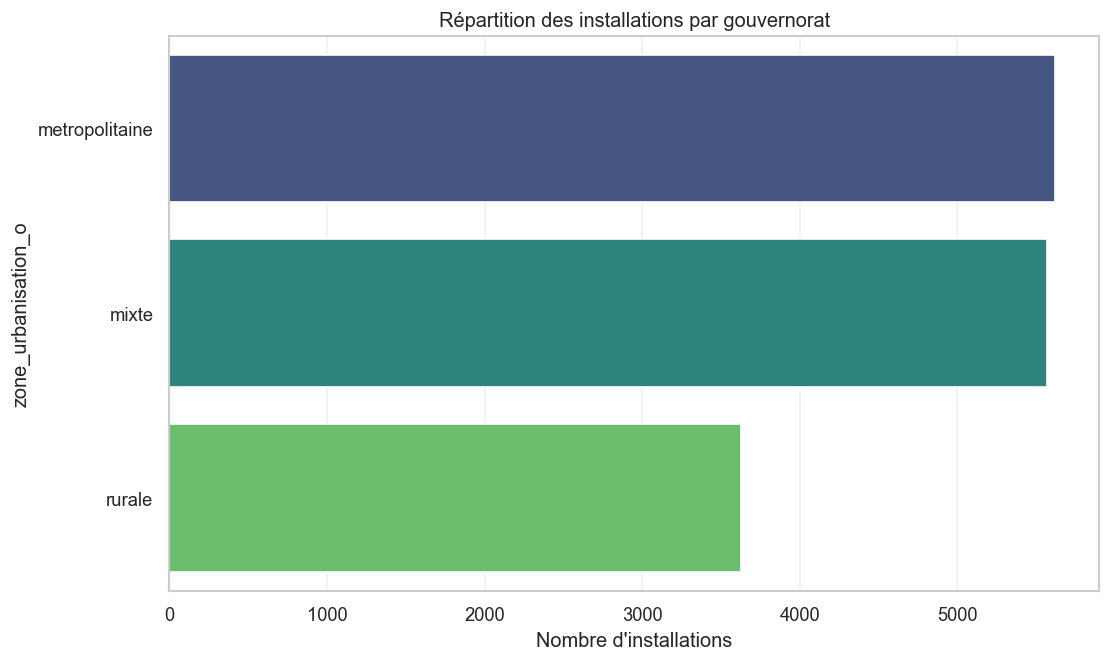

In [105]:
geo = df["zone_urbanisation_o"].value_counts().reset_index()
geo.columns = ["zone_urbanisation_o", "Installations"]

geo = geo.sort_values("Installations", ascending=False)

plt.figure()
sns.barplot(data=geo, x="Installations", y="zone_urbanisation_o", palette="viridis")

plt.title("Répartition des installations par gouvernorat")
plt.xlabel("Nombre d'installations")
plt.ylabel("zone_urbanisation_o")
plt.show()

- On constate que Mahdia à le plus d'installation

### 5.2 Distribution des installations selon le type de client :

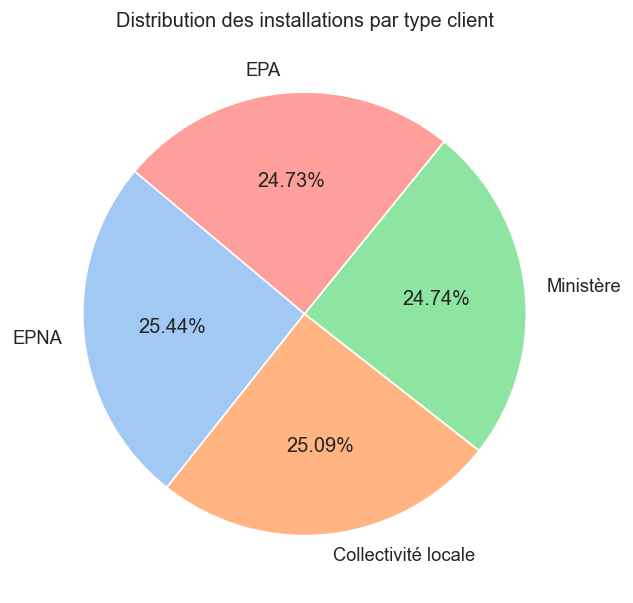

In [106]:
client = df["Type_client_o"].value_counts()

plt.figure()
plt.pie(client, labels=client.index, autopct='%1.2f%%',
        startangle=140, colors=sns.color_palette("pastel"))

plt.title("Distribution des installations par type client")
plt.show()

### 5.5 Distribution des installations en fonction de la taille du site

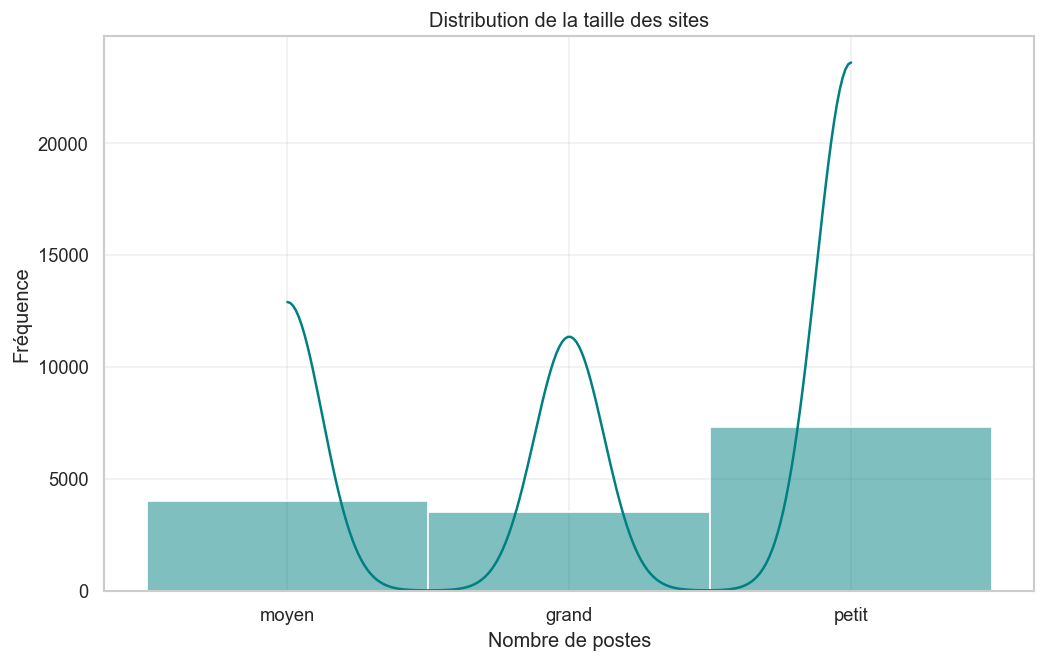

In [107]:
sns.histplot(df["cat_taille_o"], bins=20, kde=True, color="teal")

plt.title("Distribution de la taille des sites")
plt.xlabel("Nombre de postes")
plt.ylabel("Fréquence")
plt.show()

### 5.6 Distribution des versions de produits 

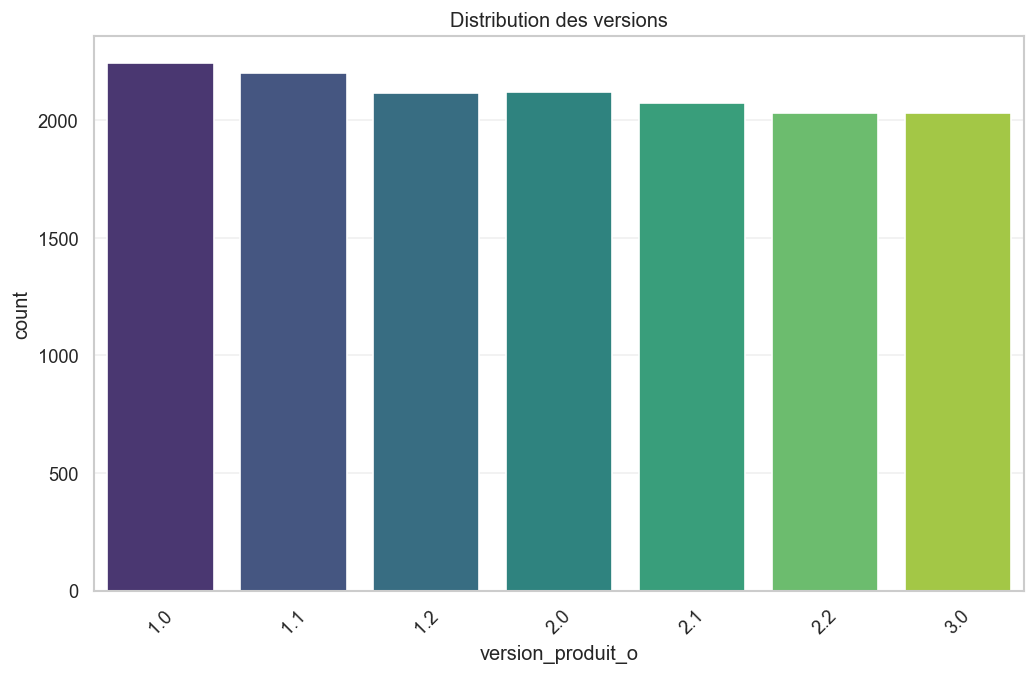

In [108]:
sns.countplot(data=df, x="version_produit_o", palette="viridis")
plt.title("Distribution des versions")
plt.xticks(rotation=45)
plt.show()

- on trouve que les versions 1.0 et 1.1 sont les plus dominantes

In [109]:
top_versions = df["version_produit_o"].value_counts().sort_values(ascending=False).head(2)
print(top_versions)
versions_obsoletes = df["version_produit_o"].value_counts().sort_values().head(2)
print(versions_obsoletes)

version_produit_o
1.0    2245
1.1    2201
Name: count, dtype: int64
version_produit_o
3.0    2030
2.2    2033
Name: count, dtype: int64


In [110]:
import plotly.express as px

fig = px.pie(
    df,
    names="client_risque",
    title="Répartition des clients à risque",
    color="client_risque",
    color_discrete_map={0: "green", 1: "red"}
)

fig.show()


In [111]:
fig = px.histogram(
    df,
    x="client_risque",
    nbins=2,
    title="Distribution du score de risque client",
    color="client_risque"
)

fig.show()


In [112]:
version_risque = df.groupby("version_produit_o")["client_risque"].mean().reset_index()
version_risque.columns = ["version_produit_o", "taux_risque"]
version_max_risque = version_risque.sort_values("taux_risque", ascending=False).head(1)
print(version_max_risque)
fig = px.bar(
    version_risque,
    x="version_produit_o",
    y="taux_risque",
    title="Taux de risque par version produit",
    color="taux_risque",
    color_continuous_scale="Reds"
)

fig.show()


   version_produit_o  taux_risque
0                1.0     0.613363


In [113]:
produit_risque = df.groupby("Nom_produit_o")["client_risque"].mean().reset_index()
produit_risque.columns = ["Nom_produit_o", "taux_risque"]
fig = px.bar(
    produit_risque,
    x="Nom_produit_o",
    y="taux_risque",
    title="Taux de risque par produit",
    color="taux_risque",
    color_continuous_scale="Reds"
)

fig.show()


In [114]:
kpi_risque = {
    "taux_clients_risque": df["client_risque"].mean(),
}
kpi_risque

{'taux_clients_risque': np.float64(0.6037251990821974)}

In [115]:
risque_vs_reussite = df.groupby("client_risque")["installation_reussie_encoded"].mean().reset_index()

fig = px.bar(
    risque_vs_reussite,
    x="client_risque",
    y="installation_reussie_encoded",
    title="Impact du risque sur la réussite",
    color="client_risque"
)
fig.show()

In [116]:
kpi_problemes = {
    "taux_pb_reseau": df["pb_reseau"].mean(),
    "taux_pb_config": df["pb_configuration"].mean(),
    "taux_pb_materiel": df["pb_materiel"].mean(),
    "taux_pb_version": df["pb_version"].mean(),
    "taux_pb_aucun": df["pb_aucun"].mean()
}

In [117]:
pb_cols = ["pb_reseau", "pb_configuration", "pb_materiel", "pb_version", "pb_aucun"]

pb_data = df[pb_cols].mean().reset_index()
pb_data.columns = ["type_probleme", "frequence"]

fig = px.bar(
    pb_data,
    x="type_probleme",
    y="frequence",
    title="Fréquence des types de problèmes",
    color="frequence"
)
fig.show()

In [118]:
kpi_cat = df.groupby("cat_debit_o").agg({
    "installation_reussie_encoded": "mean",
    "client_satisfait_encoded": "mean",
    "client_risque": "mean"
}).reset_index()
kpi_cat

,cat_debit_o,installation_reussie_encoded,client_satisfait_encoded,client_risque
0,bon,0.596428,0.560797,0.500271
1,faible,0.162996,0.063436,0.996476
2,moyen,0.158645,0.079322,0.873700


In [119]:
fig = px.bar(
    kpi_cat,
    x="cat_debit_o",
    y="installation_reussie_encoded",
    color="cat_debit_o",
    title="Impact du débit sur la réussite"
)
fig.show()

In [120]:
kpi_upgrade = df.groupby("upgrade").agg({
    "installation_reussie_encoded": "mean",
    "client_risque": "mean",
    "Duree_installation_minutes": "mean"
}).reset_index()

In [121]:
fig = px.bar(
    kpi_upgrade,
    x="upgrade",
    y="installation_reussie_encoded",
    color="upgrade",
    title="Impact des versions récentes (upgrade)"
)
fig.show()

In [122]:
os_perf = df.groupby("Systeme_exploitation_poste").agg({
    "installation_reussie_encoded": "mean",
    "os_enc": "mean"
}).reset_index()

In [123]:
fig = px.bar(
    os_perf,
    x="Systeme_exploitation_poste",
    y="installation_reussie_encoded",
    title="Performance par OS",
    color="installation_reussie_encoded"
)
fig.show()

In [124]:
kpi_causes = {
    "pb_reseau": df[df["client_risque"] == 1]["pb_reseau"].mean(),
    "pb_configuration": df[df["client_risque"] == 1]["pb_configuration"].mean(),
    "pb_materiel": df[df["client_risque"] == 1]["pb_materiel"].mean(),
    "pb_version": df[df["client_risque"] == 1]["pb_version"].mean(),
    "pb_aucun": df[df["client_risque"] == 1]["pb_aucun"].mean()
}
kpi_causes

{'pb_reseau': np.float64(0.16141292197630225),
 'pb_configuration': np.float64(0.16901408450704225),
 'pb_materiel': np.float64(0.28012519561815336),
 'pb_version': np.float64(0.4520456069751844),
 'pb_aucun': np.float64(0.0061479991057455845)}

In [125]:
df_grouped_duree = df.groupby("pb_reseau").agg({
    "Duree_installation_minutes": "mean"
}).reset_index()

fig = px.bar(
    df_grouped_duree,
    x="pb_reseau",
    y="Duree_installation_minutes",
    title="Impact problème réseau sur durée", 
    color="pb_reseau",
    color_discrete_map={0: "green", 1: "red"}
)
fig.show()

### Version a risque

In [126]:
df_grouped_version = df.groupby("version_produit_o")["client_risque"].mean().reset_index()

fig = px.bar(
    df_grouped_version,
    x="version_produit_o",
    y="client_risque",
    color="client_risque",
    title="Risque par version produit"
)
fig.show()

### Produit a risque

In [127]:
df_grouped_produit = df.groupby("Nom_produit_o")["client_risque"].mean().reset_index()

fig = px.bar(
    df_grouped_produit,
    x="Nom_produit_o",
    y="client_risque",
    color="client_risque",
    title="Risque par produit"
)
fig.show()

### Client a risque

In [128]:
variables = [
    "zone_urbanisation_o", "cat_debit_o", "cat_taille_o","Mode_installation_o", 
    "Type_client_o", "Nom_produit_o","version_produit_o",
    "pb_reseau", "pb_configuration","pb_materiel", "pb_version","pb_aucun",
    "upgrade","mois", "annee",
    "Systeme_exploitation_poste","Tentative_installation_weekend_encoded",
    "Duree_installation_minutes","nombre_reclamations_client"
]

results = []

for var in variables:
    grouped = df.groupby(var)["client_risque"].mean().reset_index()
    
    grouped = grouped.rename(columns={
        var: "modalite",
        "client_risque": "taux_risque"
    })
    
    grouped["variable"] = var
    
    grouped["modalite"] = grouped["modalite"].astype(str)
    
    results.append(grouped)

df_risk_analysis = pd.concat(results, ignore_index=True)

df_risk_analysis.head(50)

,modalite,taux_risque,variable
0,metropolitaine,0.531233,zone_urbanisation_o
1,mixte,0.572070,zone_urbanisation_o
2,rurale,0.764609,zone_urbanisation_o
3,bon,0.500271,cat_debit_o
4,faible,0.996476,cat_debit_o
5,moyen,0.873700,cat_debit_o
6,grand,0.735060,cat_taille_o
7,moyen,0.589885,cat_taille_o
8,petit,0.548153,cat_taille_o
9,Technicien_sur_site,0.616775,Mode_installation_o


In [129]:
df_risk_analysis = df_risk_analysis.copy()

# convertir toutes les colonnes interval en string
for col in df_risk_analysis.columns:
    if df_risk_analysis[col].dtype.name == "category":
        df_risk_analysis[col] = df_risk_analysis[col].astype(str)

### Top 5 causes du risque

In [130]:
importance_var = (
    df_risk_analysis
    .groupby("variable")["taux_risque"]
    .agg(["max", "min"])
)

importance_var["impact"] = importance_var["max"] - importance_var["min"]

importance_var = importance_var.sort_values("impact", ascending=False)

In [131]:
top5 = importance_var.head(5).reset_index()

In [132]:
top5["label"] = "max=" + top5["max"].round(2).astype(str)

fig = px.bar(
    top5,
    x="impact",
    y="variable",
    orientation="h",
    text="label",
    color="impact",
    title="Top 5 facteurs influençant le risque client"
)

fig.show()

### Cause exacte de chaque risque

In [133]:
for var in df_risk_analysis["variable"].unique():
    
    df_var = (
        df_risk_analysis[df_risk_analysis["variable"] == var]
        .sort_values("taux_risque", ascending=False)
        .head(5)   # top 5 seulement
    )

    fig = px.bar(
        df_var,
        x="modalite",
        y="taux_risque",
        color="taux_risque",
        title=f"Top facteurs de risque - {var}"
    )

    fig.update_layout()

    fig.show()

### 5.4 Features selection

In [134]:
df["mois"] = pd.to_datetime(df["mois"], format="%Y-%m")
df["mois_num"] = df["mois"].dt.month

# Base complète conservée pour le système d'aide à la décision (SAD)
df_sad = df.copy()

var_a_effacer =[       
       'date_installation', 'Gouvernorat', 'Id_Client', 'installation_reussie',
       'client_a_reclame', 'client_satisfait', 'Remarques',
       'Technicien_ID', 'Tentative_installation_weekend',
       'Version_precedente', 'version_produit_o',
       'score_risque', 'Nom_produit_o',
       'Type_client_o', 'Mode_installation_o', 'cat_taille_o', 'cat_debit_o',
       'zone_urbanisation_o',"mois",'cat_debit_moyen',
       'cat_taille_moyen', 'cat_taille_petit', 'cat_debit_faible','os_enc',
       'version_produit_encoded','Version_precedente'
       ]

df = df.drop(columns=var_a_effacer, errors='ignore')

In [135]:
df.columns

Index(['version_produit', 'Systeme_exploitation_poste',
       'nombre_essais_installation', 'nombre_reclamations_client',
       'Duree_installation_minutes', 'Debit_reseau_Mbps', 'Taille_site_postes',
       'pb_reseau', 'pb_configuration', 'pb_materiel', 'pb_version',
       'pb_aucun', 'annee', 'jour_semaine', 'upgrade', 'client_risque',
       'installation_reussie_encoded', 'client_satisfait_encoded',
       'client_a_reclame_encoded', 'Tentative_installation_weekend_encoded',
       'Nom_produit_INSAF', 'Nom_produit_MADANIA', 'Nom_produit_MAKATIB',
       'Type_client_EPA', 'Type_client_EPNA', 'Type_client_Ministère',
       'Mode_installation_Télémaintenance', 'zone_urbanisation_mixte',
       'zone_urbanisation_rurale', 'mois_num'],
      dtype='str')

## 6. Modelisation

In [ ]:
# ── Feature Selection ─────────────────────────────────────────────────
def feature_selection(X, y, task="classification", k=15, seuil=0.01):

    if task == "classification":
        mi = mutual_info_classif(X, y, random_state=42)
    else:
        mi = mutual_info_regression(X, y, random_state=42)

    mi_df = pd.DataFrame({
        "feature": X.columns,
        "MI": mi
    }).sort_values("MI", ascending=False)

    # ── Affichage AVANT filtre ────────────────────────────────────────
    print(f"\n📊 Toutes les features ({len(mi_df)}) :")
    print(mi_df.to_string(index=False))

    # ── Filtre ────────────────────────────────────────────────────────
    retenues  = mi_df[mi_df["MI"] >= seuil].head(k)
    eliminées = mi_df[mi_df["MI"] <  seuil]

    # ── Affichage APRÈS filtre ────────────────────────────────────────
    print(f"\n✅ Features RETENUES (MI >= {seuil}) : {len(retenues)}")
    print(retenues.to_string(index=False))

    print(f"\n❌ Features ÉLIMINÉES (MI < {seuil}) : {len(eliminées)}")
    print(eliminées["feature"].tolist())

    features_retenues = retenues["feature"].tolist()
    return features_retenues, mi_df

# ── Standardisation ───────────────────────────────────────────────────
def standardiser(X_train, X_test, cols_continues):
    cols = [c for c in cols_continues if c in X_train.columns]
    scaler = StandardScaler()
    X_train = X_train.copy()
    X_test  = X_test.copy()
    X_train[cols] = scaler.fit_transform(X_train[cols])
    X_test[cols]  = scaler.transform(X_test[cols])
    return X_train, X_test, scaler

# ── Évaluation classification ─────────────────────────────────────────
def evaluer_classifieurs(modeles, X_train, X_test, y_train, y_test):
    resultats = []
    for nom, modele in modeles.items():
        modele.fit(X_train, y_train)
        y_pred  = modele.predict(X_test)
        y_proba = modele.predict_proba(X_test)[:, 1] if hasattr(modele, "predict_proba") else None

        cv = cross_val_score(modele, X_train, y_train,
                             cv=StratifiedKFold(5), scoring="f1").mean()
        resultats.append({
            "Modèle":    nom,
            "Accuracy":  accuracy_score(y_test, y_pred),
            "F1-Score":  f1_score(y_test, y_pred),
            "ROC-AUC":   roc_auc_score(y_test, y_proba) if y_proba is not None else None,
            "CV F1":     cv
        })
    return pd.DataFrame(resultats).sort_values("F1-Score", ascending=False)

# ── Évaluation régression ─────────────────────────────────────────────
def evaluer_regresseurs(modeles, X_train, X_test, y_train, y_test):
    resultats = []
    for nom, modele in modeles.items():
        modele.fit(X_train, y_train)
        y_pred = modele.predict(X_test)

        cv = cross_val_score(modele, X_train, y_train,
                             cv=KFold(5), scoring="r2").mean()
        resultats.append({
            "Modèle": nom,
            "R²":     r2_score(y_test, y_pred),
            "MAE":    mean_absolute_error(y_test, y_pred),
            "RMSE":   np.sqrt(mean_squared_error(y_test, y_pred)),
            "CV R²":  cv
        })
    return pd.DataFrame(resultats).sort_values("R²", ascending=False)

# ── Matrice de confusion ──────────────────────────────────────────────
def plot_confusion(modele, X_test, y_test, titre):
    cm = confusion_matrix(y_test, modele.predict(X_test))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
    plt.title(f"Confusion Matrix - {titre}")
    plt.xlabel("Prédit"); plt.ylabel("Réel")
    plt.tight_layout(); plt.show()

def plot_resultats_regression(modele, X_test, y_test, titre):
    y_pred = modele.predict(X_test)
    residus = y_test - y_pred

    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    fig.suptitle(f"Évaluation du modèle - {titre}", fontsize=14, fontweight="bold")

    # ── Plot 1 : Valeurs réelles vs prédites ─────────────────────────
    ax1 = axes[0, 0]
    ax1.scatter(y_test, y_pred, alpha=0.4, color="steelblue", edgecolors="white", s=30)
    min_val = min(y_test.min(), y_pred.min())
    max_val = max(y_test.max(), y_pred.max())
    ax1.plot([min_val, max_val], [min_val, max_val],
             color="red", linestyle="--", linewidth=2, label="Prédiction parfaite")
    ax1.set_xlabel("Valeurs réelles (minutes)")
    ax1.set_ylabel("Valeurs prédites (minutes)")
    ax1.set_title("Réel vs Prédit")
    ax1.legend()

    # ── Plot 2 : Distribution des résidus ─────────────────────────────
    ax2 = axes[0, 1]
    ax2.hist(residus, bins=40, color="coral", edgecolor="white", alpha=0.8)
    ax2.axvline(0, color="red", linestyle="--", linewidth=2, label="Résidu = 0")
    ax2.axvline(residus.mean(), color="navy", linestyle="-",
                linewidth=2, label=f"Moyenne = {residus.mean():.1f}")
    ax2.set_xlabel("Résidus (réel - prédit)")
    ax2.set_ylabel("Fréquence")
    ax2.set_title("Distribution des résidus")
    ax2.legend()

    # ── Plot 3 : Résidus vs Valeurs prédites ─────────────────────────
    ax3 = axes[1, 0]
    ax3.scatter(y_pred, residus, alpha=0.4, color="mediumseagreen", edgecolors="white", s=30)
    ax3.axhline(0, color="red", linestyle="--", linewidth=2)
    ax3.set_xlabel("Valeurs prédites (minutes)")
    ax3.set_ylabel("Résidus")
    ax3.set_title("Résidus vs Prédites")

    # ── Plot 4 : Métriques résumées ───────────────────────────────────
    ax4 = axes[1, 1]
    ax4.axis("off")
    r2   = r2_score(y_test, y_pred)
    mae  = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))

    # Interprétation automatique
    if r2 >= 0.85:
        qualite = "Excellent"
    elif r2 >= 0.70:
        qualite = "Bon"
    elif r2 >= 0.50:
        qualite = "Moyen"
    else:
        qualite = "Faible"

    texte = (
        f"{'Métrique':<22} {'Valeur':>10}\n"
        f"{'─' * 34}\n"
        f"{'R²':<22} {r2:>10.3f}\n"
        f"{'MAE':<22} {mae:>9.2f} min\n"
        f"{'RMSE':<22} {rmse:>9.2f} min\n"
        f"{'Résidu moyen':<22} {residus.mean():>9.2f} min\n"
        f"{'Résidu std':<22} {residus.std():>9.2f} min\n"
        f"{'─' * 34}\n"
        f"{'Qualité':<22} {qualite:>10}\n"
    )
    ax4.text(0.1, 0.5, texte, transform=ax4.transAxes,
             fontsize=12, verticalalignment="center",
             fontfamily="monospace",
             bbox=dict(boxstyle="round", facecolor="lightyellow", alpha=0.8))
    ax4.set_title("Métriques de performance")

    plt.tight_layout()
    plt.show()

    # ── Verdict final ─────────────────────────────────────────────────
    print(f"\n{'='*45}")
    print(f"  Modèle    : {titre}")
    print(f"  R²        : {r2:.3f}  → {qualite}")
    print(f"  MAE       : {mae:.2f} min  → erreur moyenne de {mae:.0f} minutes")
    print(f"  RMSE      : {rmse:.2f} min")
    print(f"{'='*45}")
    if mae <= 10:
        print("   Le modèle prédit avec une très bonne précision")
    elif mae <= 20:
        print("   Le modèle prédit correctement (erreur acceptable)")
    elif mae <= 30:
        print("   Erreur modérée, peut être amélioré")
    else:
        print("   Erreur trop élevée, revoir les features ou le modèle")




In [137]:
from category_encoders import TargetEncoder

def target_encoding(X_train, X_test, df, target):

    y_train = df.loc[X_train.index, target]
    y_test  = df.loc[X_test.index, target]

    X_tr = X_train.copy()
    X_te = X_test.copy()

    # colonnes à encoder
    cols = ["Systeme_exploitation_poste", "version_produit"]

    encoder = TargetEncoder(cols=cols)

    X_tr[cols] = encoder.fit_transform(X_tr[cols], y_train)
    X_te[cols] = encoder.transform(X_te[cols])
    
    # supprimer anciennes colonnes
    X_tr = X_tr.drop(columns=["Systeme_exploitation_poste", "version_produit"], errors='ignore')
    X_te = X_te.drop(columns=["Systeme_exploitation_poste", "version_produit"], errors='ignore')

    return X_tr, X_te, y_train, y_test

In [138]:
import plotly.express as px

# matrice de corrélation
corr = df.corr(numeric_only=True)

fig = px.imshow(
    corr,
    text_auto=".2f",
    color_continuous_scale="RdBu_r",
    zmin=-1,
    zmax=1,
    title="Matrice de corrélation des variables"
)

fig.update_layout(
    width=1200,
    height=1100
)

fig.show()

In [139]:
CLASSIFIEURS = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree":       DecisionTreeClassifier(random_state=42),
    "Random Forest":       RandomForestClassifier(n_estimators=100, random_state=42),
    "Gradient Boosting":   GradientBoostingClassifier(random_state=42),
    "XGBoost":             XGBClassifier(eval_metric="logloss", random_state=42),
    "KNN":                 KNeighborsClassifier(),
    "SVM":                 SVC(probability=True, random_state=42),
}

REGRESSEURS = {
    "Linear Regression":   LinearRegression(),
    "Ridge":               Ridge(random_state=42),
    "Lasso":               Lasso(random_state=42),
    "Decision Tree":       DecisionTreeRegressor(random_state=42),
    "Random Forest":       RandomForestRegressor(n_estimators=100, random_state=42),
    "Gradient Boosting":   GradientBoostingRegressor(random_state=42),
    "XGBoost":             XGBRegressor(random_state=42),
}


In [140]:
targets = [
    "installation_reussie_encoded",
    "client_satisfait_encoded",
    "Duree_installation_minutes",
    "client_risque",
    "client_a_reclame_encoded" 
]

X = df.drop(columns=targets)

X_train, X_test = train_test_split(
    X,
    test_size=0.2,
    random_state=42
)

   MODÈLE 1 : client_risque

── Feature Selection ──

📊 Toutes les features (23) :
                               feature       MI
            nombre_essais_installation 0.140769
                     Debit_reseau_Mbps 0.096038
            nombre_reclamations_client 0.095002
                            pb_version 0.058850
                             pb_reseau 0.028364
                    Taille_site_postes 0.025289
              zone_urbanisation_rurale 0.021467
                           pb_materiel 0.017364
                      pb_configuration 0.014263
               zone_urbanisation_mixte 0.006490
                   Nom_produit_MADANIA 0.006013
                     Nom_produit_INSAF 0.005325
                   Nom_produit_MAKATIB 0.004247
                      Type_client_EPNA 0.001678
                 Type_client_Ministère 0.000512
                               upgrade 0.000482
                              pb_aucun 0.000000
                                 annee 0.000000
     

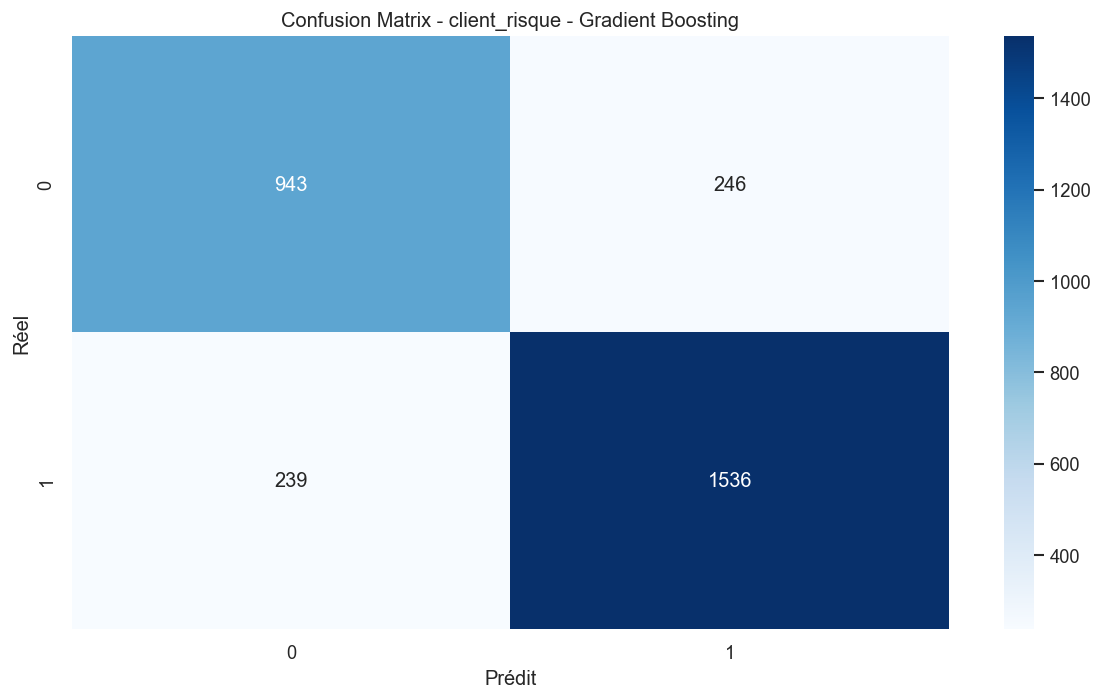

In [141]:
print("=" * 60)
print("   MODÈLE 1 : client_risque")
print("=" * 60)

y1 = df["client_risque"]

X1_train, X1_test = X_train.copy(), X_test.copy()

# ── Encoding ──
X1_train, X1_test, y1_train, y1_test = target_encoding(
    X1_train, X1_test, df, "client_risque"
)

# ── Feature Selection ──
print("\n── Feature Selection ──")

features1, mi_df = feature_selection(
    X1_train, y1_train,
    task="classification",
    k=15
)

X1_train = X1_train[features1]
X1_test  = X1_test[features1]

# ── Model ──
resultats1 = evaluer_classifieurs(
    CLASSIFIEURS,
    X1_train, X1_test,
    y1_train, y1_test
)

print(resultats1)

meilleur1_nom = resultats1.iloc[0]["Modèle"]
meilleur1 = CLASSIFIEURS[meilleur1_nom]
meilleur1.fit(X1_train, y1_train)
print(f"\n🏆 Meilleur modèle : {meilleur1_nom}")
print(classification_report(y1_test, meilleur1.predict(X1_test)))
plot_confusion(meilleur1, X1_test, y1_test, f"client_risque - {meilleur1_nom}")

In [142]:
"""print("=" * 60)
print("   MODÈLE 2 : installation_reussie")
print("=" * 60)

y2 = df["installation_reussie_encoded"]

X2_train, X2_test = X_train.copy(), X_test.copy()

X2_train, X2_test, y2_train, y2_test = target_encoding(
    X2_train, X2_test, df, "installation_reussie_encoded"
)

print("\n── Feature Selection ──")

features2, mi_df = feature_selection(
    X2_train, y2_train,
    task="classification",
    k=15
)

X2_train = X2_train[features2]
X2_test  = X2_test[features2]

resultats2 = evaluer_classifieurs(
    CLASSIFIEURS,
    X2_train, X2_test,
    y2_train, y2_test
)

print(resultats2)

meilleur2_nom = resultats2.iloc[0]["Modèle"]
meilleur2 = CLASSIFIEURS[meilleur2_nom]
meilleur2.fit(X2_train, y2_train)
print(f"\n🏆 Meilleur modèle : {meilleur2_nom}")
print(classification_report(y2_test, meilleur2.predict(X2_test)))
plot_confusion(meilleur2, X2_test, y2_test, f"installation_reussie - {meilleur2_nom}")"""

'print("=" * 60)\nprint("   MODÈLE 2 : installation_reussie")\nprint("=" * 60)\n\ny2 = df["installation_reussie_encoded"]\n\nX2_train, X2_test = X_train.copy(), X_test.copy()\n\nX2_train, X2_test, y2_train, y2_test = target_encoding(\n    X2_train, X2_test, df, "installation_reussie_encoded"\n)\n\nprint("\n── Feature Selection ──")\n\nfeatures2, mi_df = feature_selection(\n    X2_train, y2_train,\n    task="classification",\n    k=15\n)\n\nX2_train = X2_train[features2]\nX2_test  = X2_test[features2]\n\nresultats2 = evaluer_classifieurs(\n    CLASSIFIEURS,\n    X2_train, X2_test,\n    y2_train, y2_test\n)\n\nprint(resultats2)\n\nmeilleur2_nom = resultats2.iloc[0]["Modèle"]\nmeilleur2 = CLASSIFIEURS[meilleur2_nom]\nmeilleur2.fit(X2_train, y2_train)\nprint(f"\n🏆 Meilleur modèle : {meilleur2_nom}")\nprint(classification_report(y2_test, meilleur2.predict(X2_test)))\nplot_confusion(meilleur2, X2_test, y2_test, f"installation_reussie - {meilleur2_nom}")'

In [143]:
"""print("=" * 60)
print("   MODÈLE 3 : client_satisfait")
print("=" * 60)

y3 = df["client_satisfait_encoded"]

X3_train, X3_test = X_train.copy(), X_test.copy()

X3_train, X3_test, y3_train, y3_test = target_encoding(
    X3_train, X3_test, df, "client_satisfait_encoded"
)

print("\n── Feature Selection ──")

features3, mi_df = feature_selection(
    X3_train, y3_train,
    task="classification",
    k=15
)

X3_train = X3_train[features3]
X3_test  = X3_test[features3]

resultats3 = evaluer_classifieurs(
    CLASSIFIEURS,
    X3_train, X3_test,
    y3_train, y3_test
)

print(resultats3)

meilleur3_nom = resultats3.iloc[0]["Modèle"]
meilleur3 = CLASSIFIEURS[meilleur3_nom]
meilleur3.fit(X3_train, y3_train)
print(f"\n🏆 Meilleur modèle : {meilleur3_nom}")
print(classification_report(y3_test, meilleur3.predict(X3_test)))
plot_confusion(meilleur3, X3_test, y3_test, f"client_satisfait - {meilleur3_nom}")"""

'print("=" * 60)\nprint("   MODÈLE 3 : client_satisfait")\nprint("=" * 60)\n\ny3 = df["client_satisfait_encoded"]\n\nX3_train, X3_test = X_train.copy(), X_test.copy()\n\nX3_train, X3_test, y3_train, y3_test = target_encoding(\n    X3_train, X3_test, df, "client_satisfait_encoded"\n)\n\nprint("\n── Feature Selection ──")\n\nfeatures3, mi_df = feature_selection(\n    X3_train, y3_train,\n    task="classification",\n    k=15\n)\n\nX3_train = X3_train[features3]\nX3_test  = X3_test[features3]\n\nresultats3 = evaluer_classifieurs(\n    CLASSIFIEURS,\n    X3_train, X3_test,\n    y3_train, y3_test\n)\n\nprint(resultats3)\n\nmeilleur3_nom = resultats3.iloc[0]["Modèle"]\nmeilleur3 = CLASSIFIEURS[meilleur3_nom]\nmeilleur3.fit(X3_train, y3_train)\nprint(f"\n🏆 Meilleur modèle : {meilleur3_nom}")\nprint(classification_report(y3_test, meilleur3.predict(X3_test)))\nplot_confusion(meilleur3, X3_test, y3_test, f"client_satisfait - {meilleur3_nom}")'

In [144]:
"""print("=" * 60)
print("   MODÈLE 4 : client_a_reclame")
print("=" * 60)

y4 = df["client_a_reclame_encoded"]

X4_train, X4_test = X_train.copy(), X_test.copy()

X4_train, X4_test, y4_train, y4_test = target_encoding(
    X4_train, X4_test, df, "client_a_reclame_encoded"
)

print("\n── Feature Selection ──")

features4, mi_df = feature_selection(
    X4_train, y4_train,
    task="classification",
    k=15
)

X4_train = X4_train[features3]
X4_test  = X4_test[features3]

resultats4 = evaluer_classifieurs(
    CLASSIFIEURS,
    X4_train, X4_test,
    y4_train, y4_test
)

print(resultats4)

meilleur4_nom = resultats4.iloc[0]["Modèle"]
meilleur4 = CLASSIFIEURS[meilleur4_nom]
meilleur4.fit(X4_train, y4_train)
print(f"\n🏆 Meilleur modèle : {meilleur4_nom}")
print(classification_report(y4_test, meilleur4.predict(X4_test)))
plot_confusion(meilleur4, X4_test, y4_test, f"client_a_reclame - {meilleur4_nom}")"""

'print("=" * 60)\nprint("   MODÈLE 4 : client_a_reclame")\nprint("=" * 60)\n\ny4 = df["client_a_reclame_encoded"]\n\nX4_train, X4_test = X_train.copy(), X_test.copy()\n\nX4_train, X4_test, y4_train, y4_test = target_encoding(\n    X4_train, X4_test, df, "client_a_reclame_encoded"\n)\n\nprint("\n── Feature Selection ──")\n\nfeatures4, mi_df = feature_selection(\n    X4_train, y4_train,\n    task="classification",\n    k=15\n)\n\nX4_train = X4_train[features3]\nX4_test  = X4_test[features3]\n\nresultats4 = evaluer_classifieurs(\n    CLASSIFIEURS,\n    X4_train, X4_test,\n    y4_train, y4_test\n)\n\nprint(resultats4)\n\nmeilleur4_nom = resultats4.iloc[0]["Modèle"]\nmeilleur4 = CLASSIFIEURS[meilleur4_nom]\nmeilleur4.fit(X4_train, y4_train)\nprint(f"\n🏆 Meilleur modèle : {meilleur4_nom}")\nprint(classification_report(y4_test, meilleur4.predict(X4_test)))\nplot_confusion(meilleur4, X4_test, y4_test, f"client_a_reclame - {meilleur4_nom}")'

In [145]:
"""print("=" * 60)
print("   MODÈLE 5 : durée installation")
print("=" * 60)

y5 = df["Duree_installation_minutes"]

X5_train, X5_test = X_train.copy(), X_test.copy()

# ── Encoding ──
X5_train, X5_test, y5_train, y5_test = target_encoding(
    X5_train, X5_test, df, "Duree_installation_minutes"
)

print("\n── Feature Selection ──")

features5, mi_df = feature_selection(
    X5_train,
    y5_train,   
    task="regression",
    k=15
)

X5_train = X5_train[features5]
X5_test  = X5_test[features5]

resultats5 = evaluer_regresseurs(
    REGRESSEURS,
    X5_train, X5_test,
    y5_train,
    y5_test
)

print(resultats5)

meilleur5_nom = resultats5.iloc[0]["Modèle"]
meilleur5 = REGRESSEURS[meilleur5_nom]
meilleur5.fit(X5_train, y5_train)
plot_resultats_regression(meilleur5, X5_test, y5_test,
                          f"Duree_installation_minutes - {meilleur5_nom}")
print(f"\n🏆 Meilleur modèle : {meilleur5_nom}")
y5_pred = meilleur5.predict(X5_test)
print(f"R²   : {r2_score(y5_test, y5_pred):.3f}")
print(f"MAE  : {mean_absolute_error(y5_test, y5_pred):.2f} min")
print(f"RMSE : {np.sqrt(mean_squared_error(y5_test, y5_pred)):.2f} min")"""

'print("=" * 60)\nprint("   MODÈLE 5 : durée installation")\nprint("=" * 60)\n\ny5 = df["Duree_installation_minutes"]\n\nX5_train, X5_test = X_train.copy(), X_test.copy()\n\n# ── Encoding ──\nX5_train, X5_test, y5_train, y5_test = target_encoding(\n    X5_train, X5_test, df, "Duree_installation_minutes"\n)\n\nprint("\n── Feature Selection ──")\n\nfeatures5, mi_df = feature_selection(\n    X5_train,\n    y5_train,   \n    task="regression",\n    k=15\n)\n\nX5_train = X5_train[features5]\nX5_test  = X5_test[features5]\n\nresultats5 = evaluer_regresseurs(\n    REGRESSEURS,\n    X5_train, X5_test,\n    y5_train,\n    y5_test\n)\n\nprint(resultats5)\n\nmeilleur5_nom = resultats5.iloc[0]["Modèle"]\nmeilleur5 = REGRESSEURS[meilleur5_nom]\nmeilleur5.fit(X5_train, y5_train)\nplot_resultats_regression(meilleur5, X5_test, y5_test,\n                          f"Duree_installation_minutes - {meilleur5_nom}")\nprint(f"\n🏆 Meilleur modèle : {meilleur5_nom}")\ny5_pred = meilleur5.predict(X5_test)\nprin

In [146]:
"""print("\n" + "=" * 60)
print("   SYNTHÈSE FINALE")
print("=" * 60)

synthese = pd.DataFrame([
    {"Cible": "client_risque",              "Type": "Classification",
     "Meilleur modèle": meilleur1_nom,
     "F1": resultats1.iloc[0]["F1-Score"],
     "ROC-AUC": resultats1.iloc[0]["ROC-AUC"]},

    {"Cible": "installation_reussie",       "Type": "Classification",
     "Meilleur modèle": meilleur2_nom,
     "F1": resultats2.iloc[0]["F1-Score"],
     "ROC-AUC": resultats2.iloc[0]["ROC-AUC"]},

    {"Cible": "client_satisfait",           "Type": "Classification",
     "Meilleur modèle": meilleur3_nom,
     "F1": resultats3.iloc[0]["F1-Score"],
     "ROC-AUC": resultats3.iloc[0]["ROC-AUC"]},
    
    {"Cible": "client_a_reclame",           "Type": "Classification",
     "Meilleur modèle": meilleur4_nom,
     "F1": resultats4.iloc[0]["F1-Score"],
     "ROC-AUC": resultats4.iloc[0]["ROC-AUC"]},

    {"Cible": "Duree_installation_minutes", "Type": "Régression",
     "Meilleur modèle": meilleur5_nom,
     "R²": resultats5.iloc[0]["R²"],
     "RMSE": resultats5.iloc[0]["RMSE"]},
])

print(synthese.to_string(index=False))"""

'print("\n" + "=" * 60)\nprint("   SYNTHÈSE FINALE")\nprint("=" * 60)\n\nsynthese = pd.DataFrame([\n    {"Cible": "client_risque",              "Type": "Classification",\n     "Meilleur modèle": meilleur1_nom,\n     "F1": resultats1.iloc[0]["F1-Score"],\n     "ROC-AUC": resultats1.iloc[0]["ROC-AUC"]},\n\n    {"Cible": "installation_reussie",       "Type": "Classification",\n     "Meilleur modèle": meilleur2_nom,\n     "F1": resultats2.iloc[0]["F1-Score"],\n     "ROC-AUC": resultats2.iloc[0]["ROC-AUC"]},\n\n    {"Cible": "client_satisfait",           "Type": "Classification",\n     "Meilleur modèle": meilleur3_nom,\n     "F1": resultats3.iloc[0]["F1-Score"],\n     "ROC-AUC": resultats3.iloc[0]["ROC-AUC"]},\n\n    {"Cible": "client_a_reclame",           "Type": "Classification",\n     "Meilleur modèle": meilleur4_nom,\n     "F1": resultats4.iloc[0]["F1-Score"],\n     "ROC-AUC": resultats4.iloc[0]["ROC-AUC"]},\n\n    {"Cible": "Duree_installation_minutes", "Type": "Régression",\n     "Mei

## Fine-tuning

## Systéme d'aide à la décision

In [147]:
"""# Vriables importantes % ML
importance_df = pd.DataFrame({
    "feature_ml": X1_train.columns,
    "importance_ml": meilleur1.feature_importances_
})

def mapper_feature_metier(feature):

    mapping = {
        "Nom_produit_": "Nom_produit",
        "Type_client_": "Type_client",
        "Mode_installation_": "Mode_installation",
        "zone_urbanisation_": "zone_urbanisation",
    }

    for prefix, metier in mapping.items():
        if feature.startswith(prefix):
            return metier

    return feature

# Variables importantes % kpi

importance_df["variable_metier"] = importance_df["feature_ml"].apply(mapper_feature_metier)

importance_metier = (
    importance_df
    .groupby("variable_metier")["importance_ml"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)
importance_metier

impact_dashboard = importance_var.reset_index()[["variable", "impact"]]
impact_dashboard

# Variables importantes % ML et KPI
# score_global = 0.6 * importance_ML + 0.4 * importance_metier

analyse_globale = importance_metier.merge(
    impact_dashboard,
    left_on="variable_metier",
    right_on="variable",
    how="outer"
)
analyse_globale

analyse_globale["score_global"] = (
    0.6 * analyse_globale["importance_ml"].fillna(0)
    +
    0.4 * analyse_globale["impact"].fillna(0)
)

analyse_globale = analyse_globale.sort_values(
    "score_global",
    ascending=False
)

analyse_globale

# Calcul du degrée d'importance de chaque variables

def normaliser_impact_en_poids(df_impact, col="impact"):

    df = df_impact.copy()

    min_val = df[col].min()
    max_val = df[col].max()

    df["poids"] = 1 + 4 * (df[col] - min_val) / (max_val - min_val)

    df["poids"] = df["poids"].round().astype(int)

    return df

importance_var_reset = importance_var.reset_index()

df_poids = normaliser_impact_en_poids(importance_var_reset, "impact")

poids_dict = dict(zip(df_poids["variable"], df_poids["poids"]))
poids_dict

# Causes client à risque

def identifier_causes_client(row, poids_dict):

    causes = []

    if row["pb_reseau"] == 1:
        causes.append(("Problème réseau", poids_dict.get("pb_reseau", 1)))

    if row["pb_configuration"] == 1:
        causes.append(("Problème configuration", poids_dict.get("pb_configuration", 1)))

    if row["pb_materiel"] == 1:
        causes.append(("Problème matériel", poids_dict.get("pb_materiel", 1)))

    if row["pb_version"] == 1:
        causes.append(("Incompatibilité version", poids_dict.get("pb_version", 1)))

    if row["cat_debit_o"] == "faible":
        causes.append(("Débit réseau faible", poids_dict.get("cat_debit_o", 1)))

    if row["cat_taille_o"] == "grand":
        causes.append(("Site de grande taille", poids_dict.get("cat_taille_o", 1)))

    if row["zone_urbanisation_o"] == "rurale":
        causes.append(("Zone rurale / accès complexe", poids_dict.get("zone_urbanisation_o", 1)))

    if row["Duree_installation_minutes"] > 120:
        causes.append(("Installation longue", 3))

    if row["nombre_reclamations_client"] >= 2:
        causes.append(("Historique de réclamations élevé", poids_dict.get("nombre_reclamations_client", 5)))

    if row["upgrade"] == 1:
        causes.append(("Upgrade produit complexe", poids_dict.get("upgrade", 1)))
    
    if row["version_produit_o"].isin([1.0,2.0,2.3]):
        causes.append("Version à risque",2)
        
    if row["Systeme_exploitation_poste"] == "WindowsXP":
        causes.append("Probléme OS",2)
        
    return sorted(causes, key=lambda x: x[1], reverse=True)

# Recommandations

def generer_recommandations(row):

    recs = []

    if row["pb_reseau"] == 1:
        recs.append(("Audit réseau", 5))

    if row["cat_debit_o"] == "faible":
        recs.append(("Augmenter débit réseau", 4))

    if row["pb_configuration"] == 1:
        recs.append(("Reconfigurer poste client", 4))

    if row["pb_materiel"] == 1:
        recs.append(("Maintenance/remplacement matériel", 4))

    if row["pb_version"] == 1:
        recs.append(("Mettre à jour version produit", 4))

    if row["cat_taille_o"] == "grand":
        recs.append(("Affecter équipe senior", 3))

    if row["zone_urbanisation_o"] == "rurale":
        recs.append(("Planifier déplacement anticipé", 2))

    if row["Tentative_installation_weekend_encoded"] == 1:
        recs.append(("Replanifier hors weekend", 2))

    return recs

# Prioritée des recommandations
def prioriser_actions(recommandations, proba_risque):

    actions = []

    for action, base in recommandations:

        score = round(base * proba_risque, 2)

        actions.append({
            "action": action,
            "priorite": score
        })

    return sorted(actions, key=lambda x: x["priorite"], reverse=True)

# SAD
def systeme_aide_decision(row, proba_risque, poids_dict):

    causes = identifier_causes_client(row, poids_dict)

    recommandations = generer_recommandations(row)

    actions_priorisees = prioriser_actions(
        recommandations,
        proba_risque
    )

    return {
        "risque": round(proba_risque, 3),
        "causes": causes,
        "actions": actions_priorisees
    }

# Résultat
df_sad["proba_risque"] = np.nan
df_sad.loc[X1_test.index, "proba_risque"] = meilleur1.predict_proba(X1_test)[:, 1]

resultats_sad = []

for idx in X1_test.index:
    row = df_sad.loc[idx]
    resultat = systeme_aide_decision(
        row,
        row["proba_risque"],
        poids_dict
    )
    resultats_sad.append(resultat)

resultats_sad"""

'# Vriables importantes % ML\nimportance_df = pd.DataFrame({\n    "feature_ml": X1_train.columns,\n    "importance_ml": meilleur1.feature_importances_\n})\n\ndef mapper_feature_metier(feature):\n\n    mapping = {\n        "Nom_produit_": "Nom_produit",\n        "Type_client_": "Type_client",\n        "Mode_installation_": "Mode_installation",\n        "zone_urbanisation_": "zone_urbanisation",\n    }\n\n    for prefix, metier in mapping.items():\n        if feature.startswith(prefix):\n            return metier\n\n    return feature\n\n# Variables importantes % kpi\n\nimportance_df["variable_metier"] = importance_df["feature_ml"].apply(mapper_feature_metier)\n\nimportance_metier = (\n    importance_df\n    .groupby("variable_metier")["importance_ml"]\n    .sum()\n    .sort_values(ascending=False)\n    .reset_index()\n)\nimportance_metier\n\nimpact_dashboard = importance_var.reset_index()[["variable", "impact"]]\nimpact_dashboard\n\n# Variables importantes % ML et KPI\n# score_global = 

In [148]:
meilleur1.fit(X1_train, y1_train)

,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'The function to measure the quality of a split. Supported criteria are'friedman_mse' for the mean squared error with improvement score byFriedman, 'squared_error' for mean squared error. The default value of'friedman_mse' is generally the best as it can provide a betterapproximation in some cases... versionadded:: 0.18",'friedman_mse'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, 

In [149]:
import shap
explainer = shap.TreeExplainer(meilleur1)
shap_values = explainer.shap_values(X1_test)

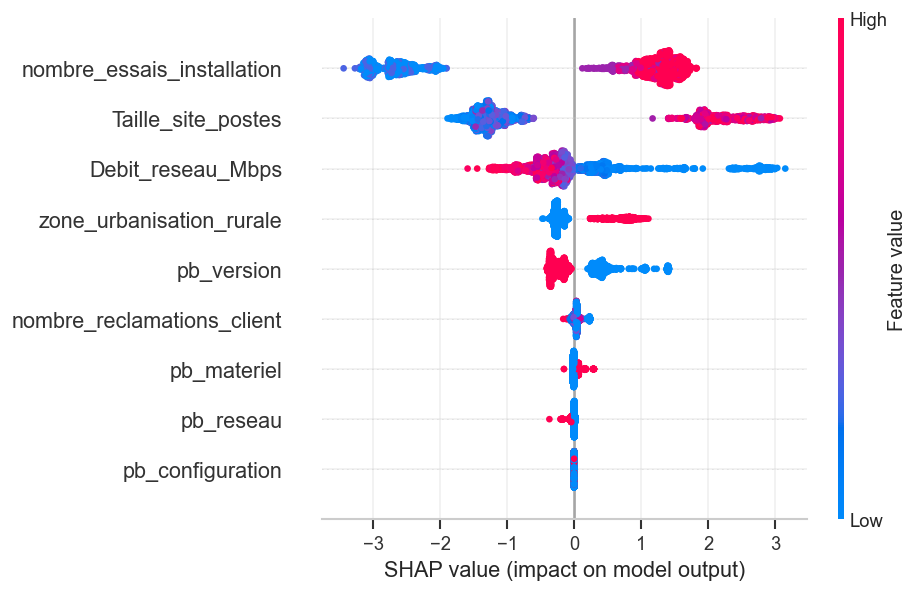

In [150]:
shap.summary_plot(shap_values, X1_test)

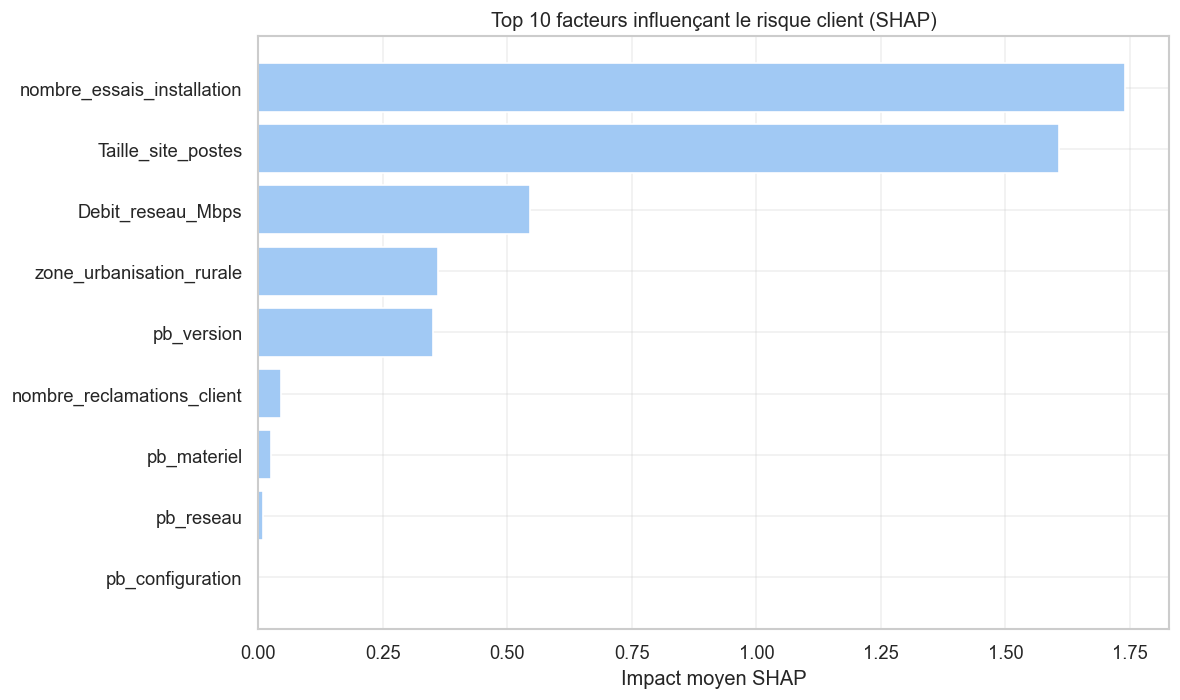

In [151]:
vals = shap_values[1] if isinstance(shap_values, list) else shap_values

importance = pd.DataFrame({
    "feature": X1_test.columns,
    "importance": np.abs(vals).mean(axis=0)
}).sort_values("importance", ascending=False)

plt.figure(figsize=(10,6))
plt.barh(importance["feature"].head(10), importance["importance"].head(10))
plt.gca().invert_yaxis()
plt.title("Top 10 facteurs influençant le risque client (SHAP)")
plt.xlabel("Impact moyen SHAP")
plt.tight_layout()
plt.show()

In [152]:
def shap_json(shap_values, X, i):

    vals = shap_values[1][i] if isinstance(shap_values, list) else shap_values[i]

    df = pd.DataFrame({
        "feature": X.columns,
        "impact": vals
    })

    df = df.sort_values("impact", key=abs, ascending=False)

    return [
        {
            "cause": row.feature,
            "impact": round(row.impact, 3),
            "direction": "risk_up" if row.impact > 0 else "risk_down"
        }
        for row in df.head(5).itertuples()
    ]

In [153]:
def shap_ui_format(shap_values, X, i):

    vals = shap_values[1][i] if isinstance(shap_values, list) else shap_values[i]

    df = pd.DataFrame({
        "feature": X.columns,
        "value": vals
    })

    df = df.sort_values("value", key=abs, ascending=False)

    return {
        "top_causes": [
            {
                "label": row.feature,
                "value": round(row.value, 3),
                "type": "risk_increase" if row.value > 0 else "risk_decrease"
            }
            for row in df.head(5).itertuples()
        ]
    }

In [154]:
shap_ui_format(shap_values,X1_test,1)

{'top_causes': [{'label': 'Taille_site_postes',
   'value': 2.724,
   'type': 'risk_increase'},
  {'label': 'nombre_essais_installation',
   'value': 1.282,
   'type': 'risk_increase'},
  {'label': 'pb_version', 'value': -0.227, 'type': 'risk_decrease'},
  {'label': 'zone_urbanisation_rurale',
   'value': -0.148,
   'type': 'risk_decrease'},
  {'label': 'Debit_reseau_Mbps', 'value': -0.12, 'type': 'risk_decrease'}]}

In [155]:
def plot_client_waterfall(i):
    # Get SHAP values for this instance
    if isinstance(shap_values, list):
        vals = shap_values[1][i]
    else:
        vals = shap_values[i]
    
    # Get base value - handle both scalar and array cases
    base_val = explainer.expected_value
    if isinstance(base_val, np.ndarray):
        base_val = float(base_val[0] if len(base_val) == 1 else base_val[1])
    
    shap.plots.waterfall(
        shap.Explanation(
            values=vals,
            base_values=base_val,
            data=X1_test.iloc[i],
            feature_names=X1_test.columns
        )
    )

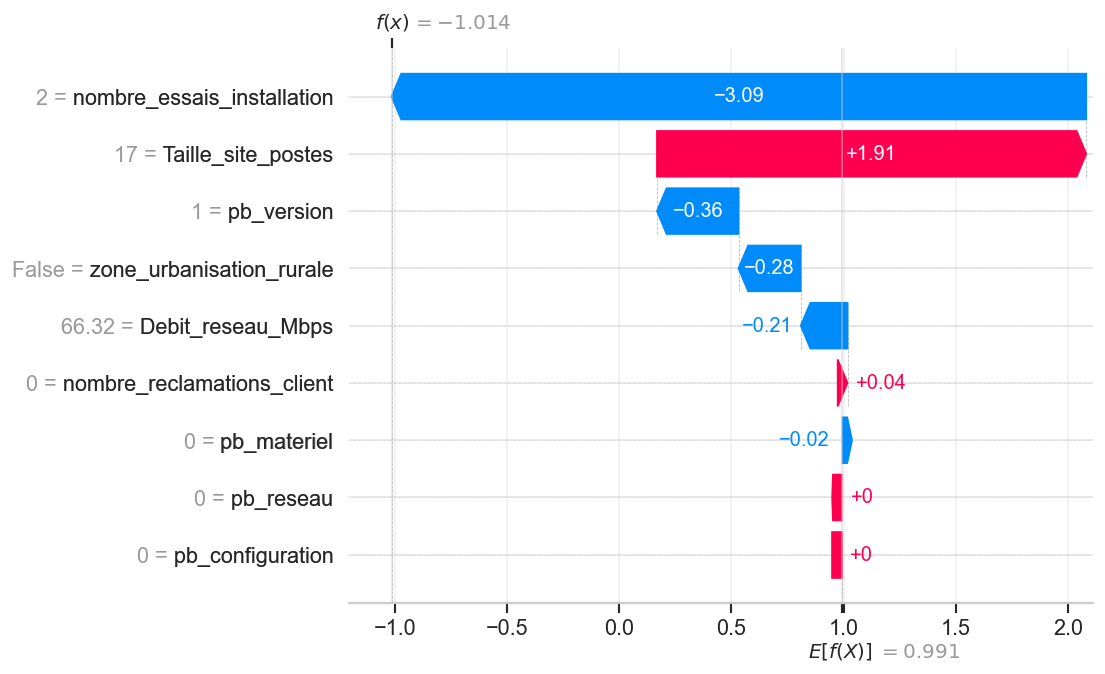

In [156]:
plot_client_waterfall(6)

In [157]:
def get_shap_explanation(i):

    vals = shap_values[1][i] if isinstance(shap_values, list) else shap_values[i]

    df = pd.DataFrame({
        "feature": X1_test.columns,
        "impact": vals
    })

    df["abs"] = df["impact"].abs()
    df = df.sort_values("abs", ascending=False).head(3)

    return [
        f"{row.feature} ({round(row.impact, 2)})"
        for row in df.itertuples()
    ]

In [ ]:
def generer_recommandations(row):

    recs = []

    if row["pb_reseau"] == 1:
        recs.append("Audit réseau")

    if row["cat_debit_o"] == "faible":
        recs.append("Augmenter débit réseau")

    if row["pb_configuration"] == 1:
        recs.append("Reconfigurer poste du client")

    if row["pb_materiel"] == 1:
        recs.append("Maintenance/remplacement matériel")

    if  row["pb_version"] == 1 or  row["upgrade"] == 0 :
        recs.append("Mettre à jour version produit")

    if row["cat_taille_o"] == "grand":
        recs.append("Le poste est tellement grand que ça complique l'installation, changer l'infrastructure du client")

    if row["zone_urbanisation_o"] == "rurale":
        recs.append("Planifier déplacement anticipé")

    if row["Tentative_installation_weekend_encoded"] == 1:
        recs.append("Replanifier hors weekend")

    if row["systeme_exploitation_poste"] in ["WindowsXP", "Win7", "Win8", "Windows 2012 Server", "Windows 2016 Server"]:
        recs.append("Mettre à jour le système d'exploitation du poste client")

    return recs

In [159]:
def prioriser_actions(recommandations, proba):

    return [
        {
            "action": r,
            "priorite": round(proba * (5 - i*0.5), 2)
        }
        for i, r in enumerate(recommandations[:3])
    ]

In [160]:
df_sad["proba_risque"] = np.nan
df_sad.loc[X1_test.index, "proba_risque"] = meilleur1.predict_proba(X1_test)[:, 1]
resultats_sad = []

for i, idx in enumerate(X1_test.index):

    row = df_sad.loc[idx]

    resultats_sad.append({
        "client_id": idx,
        "risque": round(row["proba_risque"], 3),

        "top_causes": get_shap_explanation(i),

        "top_actions": prioriser_actions(
            generer_recommandations(row),
            row["proba_risque"]
        )
    })

In [161]:
df_dashboard = pd.DataFrame([
    {
        "client_id": r["client_id"],
        "risque": r["risque"],

        "top_causes": " | ".join(r["top_causes"]),

        "top_actions": " - ".join(
            [a["action"] for a in r["top_actions"]]
        )
    }
    for r in resultats_sad
])


In [165]:
df_dashboard.head()

,client_id,risque,top_causes,top_actions
0,12374,0.967,Taille_site_postes (2.11) | nombre_essais_inst...,Maintenance/remplacement matériel - La poste e...
1,12167,0.989,Taille_site_postes (2.72) | nombre_essais_inst...,Mettre à jour version produit - La poste est t...
2,2693,0.917,nombre_essais_installation (1.32) | Taille_sit...,Reconfigurer poste client - Planifier déplacem...
3,1383,0.993,Taille_site_postes (1.94) | nombre_essais_inst...,Maintenance/remplacement matériel - La poste e...
4,11042,0.021,nombre_essais_installation (-2.53) | Taille_si...,Mettre à jour version produit
